# Recall-first prediction of death during follow-up in TCGA-BRCA: SHAP explanations and a Black-vs-White fairness audit

**MSc project, Dept. of Computer Science, University of Jos** - *Utilizing SHAP to explain XGBoost for breast cancer* (revised proposal).

This notebook runs the **primary specification** (the revised proposal's Table 3.2 predictors) with the same `brca_xai` package that
`run_pipeline.py` and the dashboard use, and ends by comparing it with the **audit-hardened** specification. Interpretation sentences are *generated from the
results*. Runtime: about 6-7 minutes.

| Section | Proposal item | Question |
|---|---|---|
| 1 | 3.2.1 | Who is in the cohort? |
| 2 | 3.2.2-3.2.3 | Which columns may a model use? What do blanks do? |
| 3 | 3.2.4 | Model, tuning, class imbalance, overfitting control, recall-first threshold |
| 4 | 3.2.5 | Hold-out performance with confidence intervals; baselines |
| 5 | 3.2.6 | SHAP: global, local, fidelity, stability, clinical alignment, race check |
| 6 | extension | Fairness audit and mitigation (Black vs White) |
| 7 | 3.2.11 | Robustness; survival check |
| 8 | - | As-proposed vs audit-hardened specification |

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, joblib
from IPython.display import display, Image, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
from brca_xai import data as D, modeling as M, fairness as F, plots
from brca_xai.pipeline import Study, ART_ROOT
s = Study("proposal")
s.fig = ROOT / "reports" / "notebook_figures" / "proposal"      # the notebook never overwrites the thesis figures or artifacts
def show(name, w=800): display(Image(filename=str(s.fig / name), width=w))
def say(t): display(Markdown(t))

## 1. Cohort (proposal 3.2.1)

In [2]:
s.load()
f = s.res["flow"]
say(f"**{f['n_records']:,}** patients, **{f['n_deaths']}** deaths ({f['prevalence']:.1%}). Median follow-up {f['median_followup']:.0f} months (max {f['max_followup']:.0f}); "
    f"{f['living_lt60']:.0%} of living patients have under 60 months of follow-up. Fairness audit groups: {f['n_white']} White ({f['deaths_white']} deaths), "
    f"{f['n_black']} Black ({f['deaths_black']} deaths); {f['n_other']} Asian / race not recorded are used for training only. "
    f"80/20 split: {f['n_dev']} development / **{f['n_test']}** hold-out ({f['test_deaths']} deaths, only {f['test_black_deaths']} of them Black).")
display(s.table1)

**1,084** patients, **151** deaths (13.9%). Median follow-up 27 months (max 283); 79% of living patients have under 60 months of follow-up. Fairness audit groups: 751 White (111 deaths), 182 Black (30 deaths); 151 Asian / race not recorded are used for training only. 80/20 split: 867 development / **217** hold-out (30 deaths, only 6 of them Black).

,characteristic,All,White,Black,Other
0,"Patients, n",1084,751,182,151
1,"Deaths during follow-up, n (%)",151 (13.9%),111 (14.8%),30 (16.5%),10 (6.6%)
2,"Age, median (IQR)",58 (49-67),59 (49-67),54 (47-67),59 (50-69)
3,"Follow-up months, median (IQR)",27 (15-55),32 (17-62),27 (15-54),13 (11-31)
4,T1,277 (26%),209 (28%),50 (27%),18 (12%)
5,T2,628 (58%),419 (56%),105 (58%),104 (69%)
6,T3,137 (13%),100 (13%),19 (10%),18 (12%)
7,T4,39 (4%),22 (3%),6 (3%),11 (7%)
8,T unknown (TX),3 (0%),1 (0%),2 (1%),0 (0%)
9,N0,512 (47%),356 (47%),89 (49%),67 (44%)


## 2. Variable selection, leakage control and preprocessing (proposal 3.2.2-3.2.3)

All 38 columns get an explicit decision. The audit then asks whether the *blanks* of the retained columns carry the outcome.

In [3]:
display(s.governance.groupby("decision").size().to_frame("columns"))
display(s.governance)

,columns
decision,
Excluded: outcome-related (leakage),10
Excluded: redundant or sparse,5
Excluded: uninformative or constant,11
Included (predictor),10
Target,1


,column,decision,reason,audit_note
0,AGE,Included (predictor),-> age,
1,SUBTYPE,Included (predictor),-> sub_*,103 missing; native missing
2,PATH_T_STAGE,Included (predictor),-> t_stage,TX -> missing
3,PATH_N_STAGE,Included (predictor),-> n_stage,NX -> missing; NX has a 61 % death rate (audit)
4,PATH_M_STAGE,Included (predictor),-> m_stage,MX -> missing
5,ICD_O_3_HISTOLOGY,Included (predictor),-> histology_*,ductal / lobular / other
6,RACE,Included (predictor),"-> race_black, race_asian",also the fairness group; 90 not recorded
7,RADIATION_THERAPY,Included (predictor),-> radiation,101 blanks; death rate 42 % when blank vs 11 % recorded -> informative missingness (au...
8,HISTORY_NEOADJUVANT_TRTYN,Included (predictor),-> neoadjuvant,only 6 'Yes'
9,PRIOR_DX,Included (predictor),-> prior_dx,


In [4]:
display(s.missingness.round(3))
r = s.missingness.set_index("column").loc["RADIATION_THERAPY"]
say(f"*Radiation therapy is blank for {int(r.n_missing)} patients, {r.death_rate_missing:.0%} of whom died, against {r.death_rate_recorded:.0%} when it is recorded. "
    "XGBoost handles blanks natively, so it will learn this: a documentation pattern, not biology.*")

,column,n_missing,pct_missing,death_rate_missing,death_rate_recorded
0,SUBTYPE,103,9.502,0.184,0.135
1,RADIATION_THERAPY,101,9.317,0.416,0.111
2,ETHNICITY,169,15.590,0.059,0.154
3,PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT,364,33.579,0.148,0.135
4,RACE,90,8.303,0.078,0.145
5,PERSON_NEOPLASM_CANCER_STATUS,123,11.347,0.211,0.130
6,NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT,199,18.358,0.281,0.107
7,AJCC_STAGING_EDITION,140,12.915,0.121,0.142
8,DAYS_LAST_FOLLOWUP,104,9.594,1.000,0.048
9,PATH_N_STAGE = NX,20,1.845,0.550,0.132


*Radiation therapy is blank for 101 patients, 42% of whom died, against 11% when it is recorded. XGBoost handles blanks natively, so it will learn this: a documentation pattern, not biology.*

## 3. Model development (proposal 3.2.4)

In [5]:
s.tune()
say(f"Bayesian (TPE) search, {s.n_trials} trials, repeated stratified 5-fold CV on the development set. Chosen: depth {s.params['max_depth']}, "
    f"{s.params['n_estimators']} trees, learning rate {s.params['learning_rate']:.3f}. Class weight scale_pos_weight = {s.res['flow']['spw']:.1f} (no oversampling).")
display(s.tuning.head(6)[["max_depth", "n_estimators", "learning_rate", "auc", "fpr_at_80_recall"]].round(3))

[17:30:41] [proposal] Bayesian tuning on the development set ...


Bayesian (TPE) search, 60 trials, repeated stratified 5-fold CV on the development set. Chosen: depth 2, 299 trees, learning rate 0.023. Class weight scale_pos_weight = 6.2 (no oversampling).

,max_depth,n_estimators,learning_rate,auc,fpr_at_80_recall
0,2,299,0.023,0.750,0.467
1,2,317,0.023,0.748,0.470
2,2,320,0.018,0.749,0.472
3,2,356,0.029,0.750,0.474
4,2,314,0.018,0.748,0.476
5,2,311,0.019,0.748,0.476


[17:31:15] [proposal] benchmark ...


[17:31:51] leakage ladder, artefact ablation, specification comparison, survival check ...


,rung,note,auc,pr_auc,precision_at_80_recall
0,0 Audit-hardened features,"Age, T, N (NX->N0), M (MX->M0), PAM50, histology, prior dx, race",0.666,0.314,0.181
1,1 Proposal Table 3.2 predictors (as specified),"Adds radiation therapy, neoadjuvant; NX / MX / TX left missing",0.758,0.466,0.209
2,2 + ethnicity and node-assessment,Excluded by the proposal: blanks track the outcome,0.768,0.476,0.220
3,3 + tumour status & new tumour event at follow-up,Outcome proxies recorded after diagnosis,0.880,0.636,0.384
4,4 + days to last follow-up,Blank for every patient who died,0.945,0.891,0.798


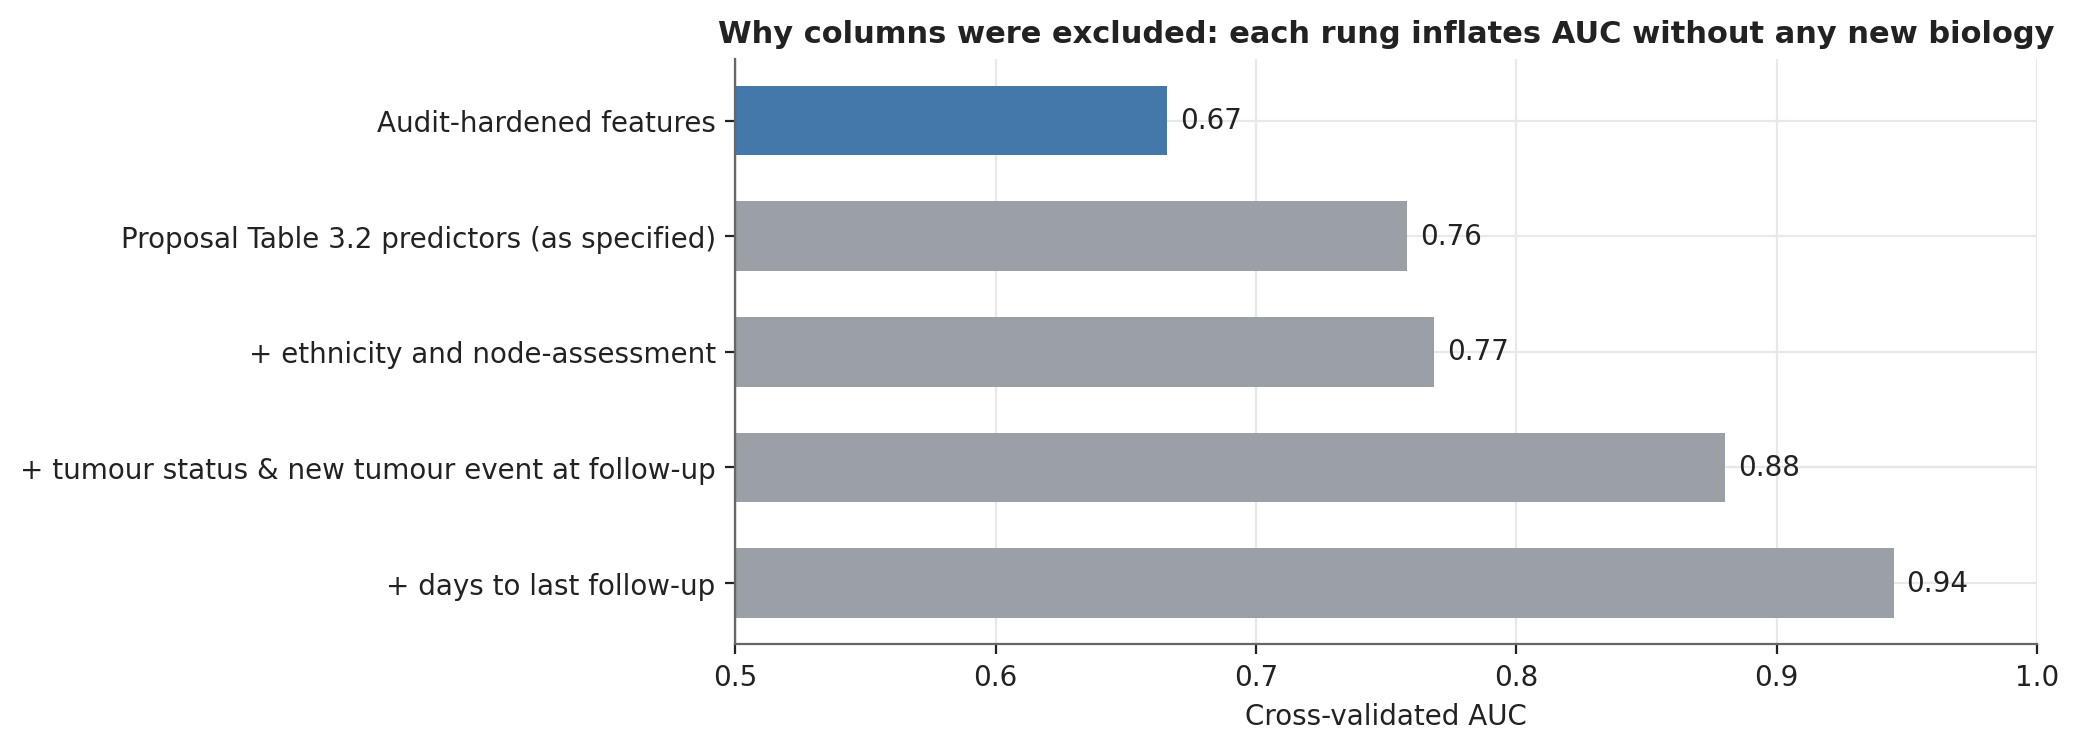

In [6]:
s.audit_models()
display(s.ladder[["rung", "note", "auc", "pr_auc", "precision_at_80_recall"]].round(3))
plots.fig_leakage(s, s.fig); show("02_leakage_ladder.png", 800)

,variant,auc,pr_auc
0,Proposal predictors (as specified),0.758,0.466
1,minus radiation therapy (blank = 42 % death),0.699,0.343
2,minus race recorded / not recorded signal (unknown -> White),0.746,0.394
3,"minus NX / MX codes (NX -> N0, MX -> M0)",0.737,0.445
4,minus all three artefacts,0.648,0.294
5,minus all three and neoadjuvant (= audit-hardened),0.649,0.298
6,race-blind proposal predictors,0.738,0.389


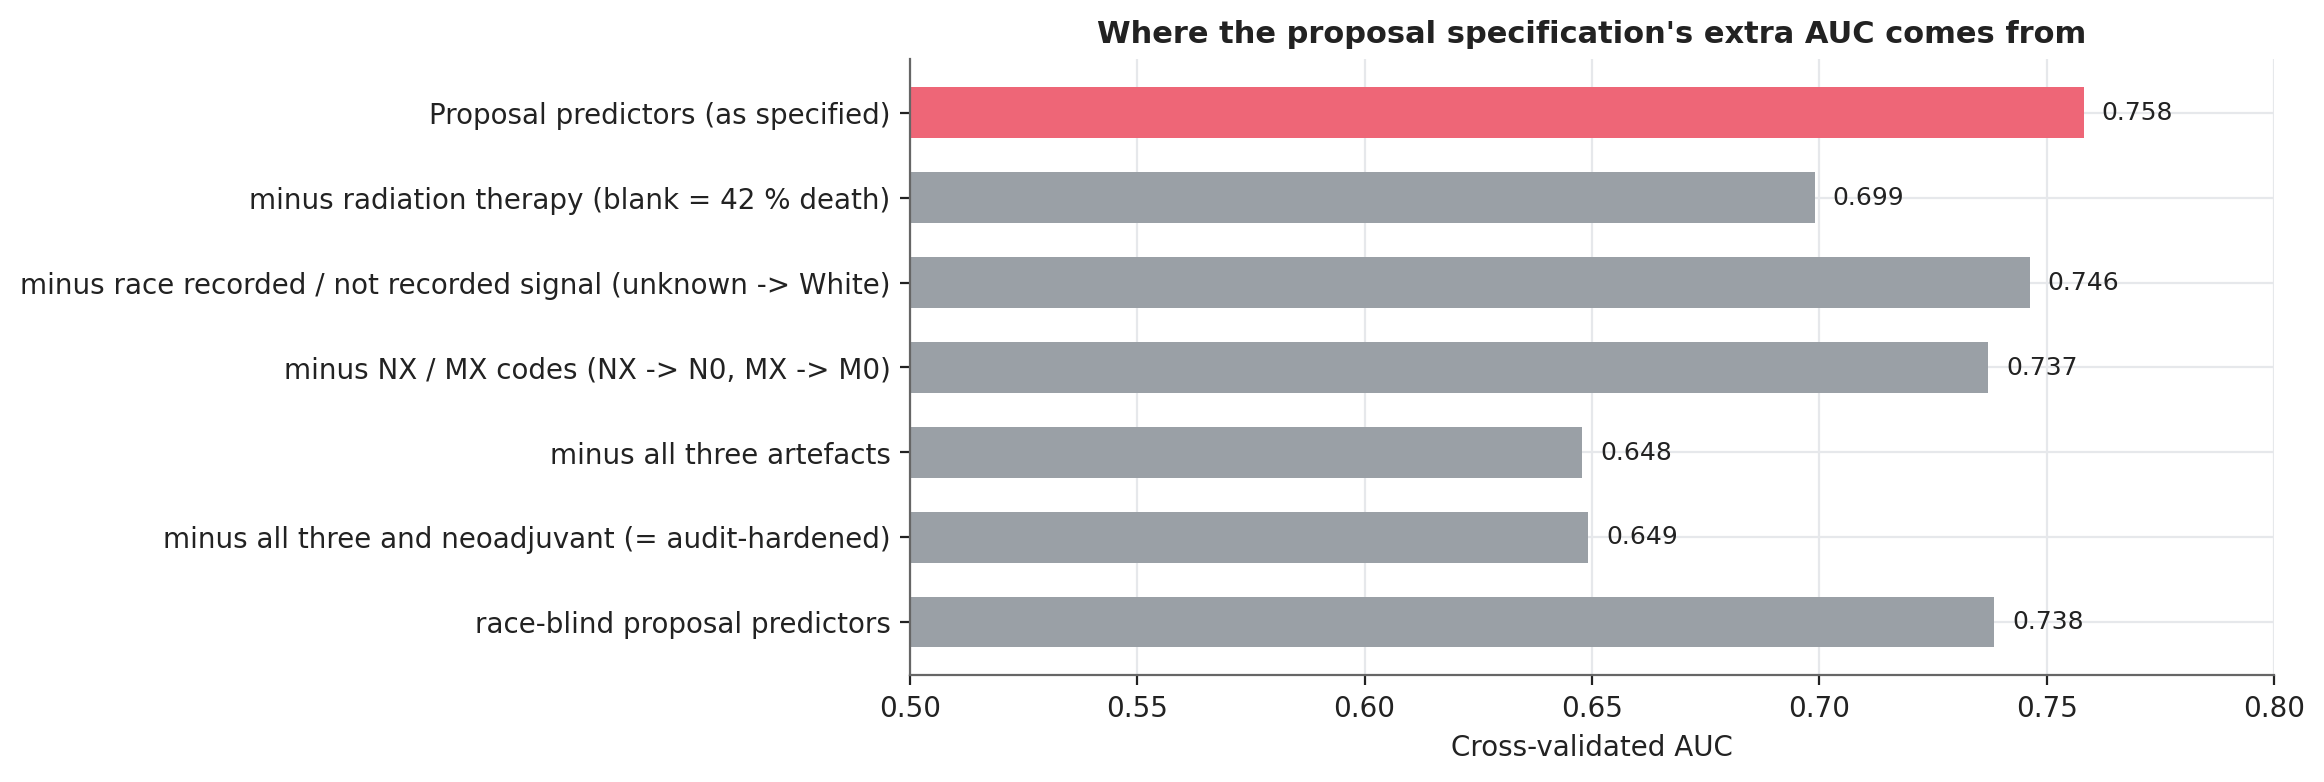

,spec,n_features,auc,pr_auc,fpr_at_80_recall
0,proposal,16,0.758,0.466,0.490
1,stage_group,14,0.706,0.366,0.551
2,hardened,14,0.666,0.314,0.586
3,complete_case_subtype,16,0.752,0.468,0.493


*Part of the proposal specification's discrimination is documentation, not biology. Sections 4-6 therefore report the specification as proposed and the audit-hardened one side by side.*

In [7]:
display(s.ablation[["variant", "auc", "pr_auc"]].round(3)); plots.fig_ablation(s, s.fig); show("24_artefact_ablation.png", 800)
display(s.spec_table[["spec", "n_features", "auc", "pr_auc", "fpr_at_80_recall"]].round(3))
say("*Part of the proposal specification's discrimination is documentation, not biology. Sections 4-6 therefore report the specification as proposed and the audit-hardened one side by side.*")

,model,auc,auc_sd,pr_auc,fpr_at_80_recall,precision_at_80_recall,auc_White,auc_Black
0,Stage-only (logistic),0.538,0.005,0.175,0.853,0.135,0.537,0.582
1,Logistic regression,0.755,0.007,0.444,0.489,0.210,0.772,0.708
2,Random forest,0.734,0.007,0.417,0.515,0.201,0.749,0.680
3,XGBoost (defaults),0.754,0.004,0.456,0.487,0.210,0.761,0.740
4,"XGBoost (tuned, no monotone constraint)",0.756,0.005,0.464,0.491,0.209,0.767,0.723
5,"XGBoost (tuned, monotone) - used",0.758,0.005,0.466,0.490,0.209,0.767,0.729


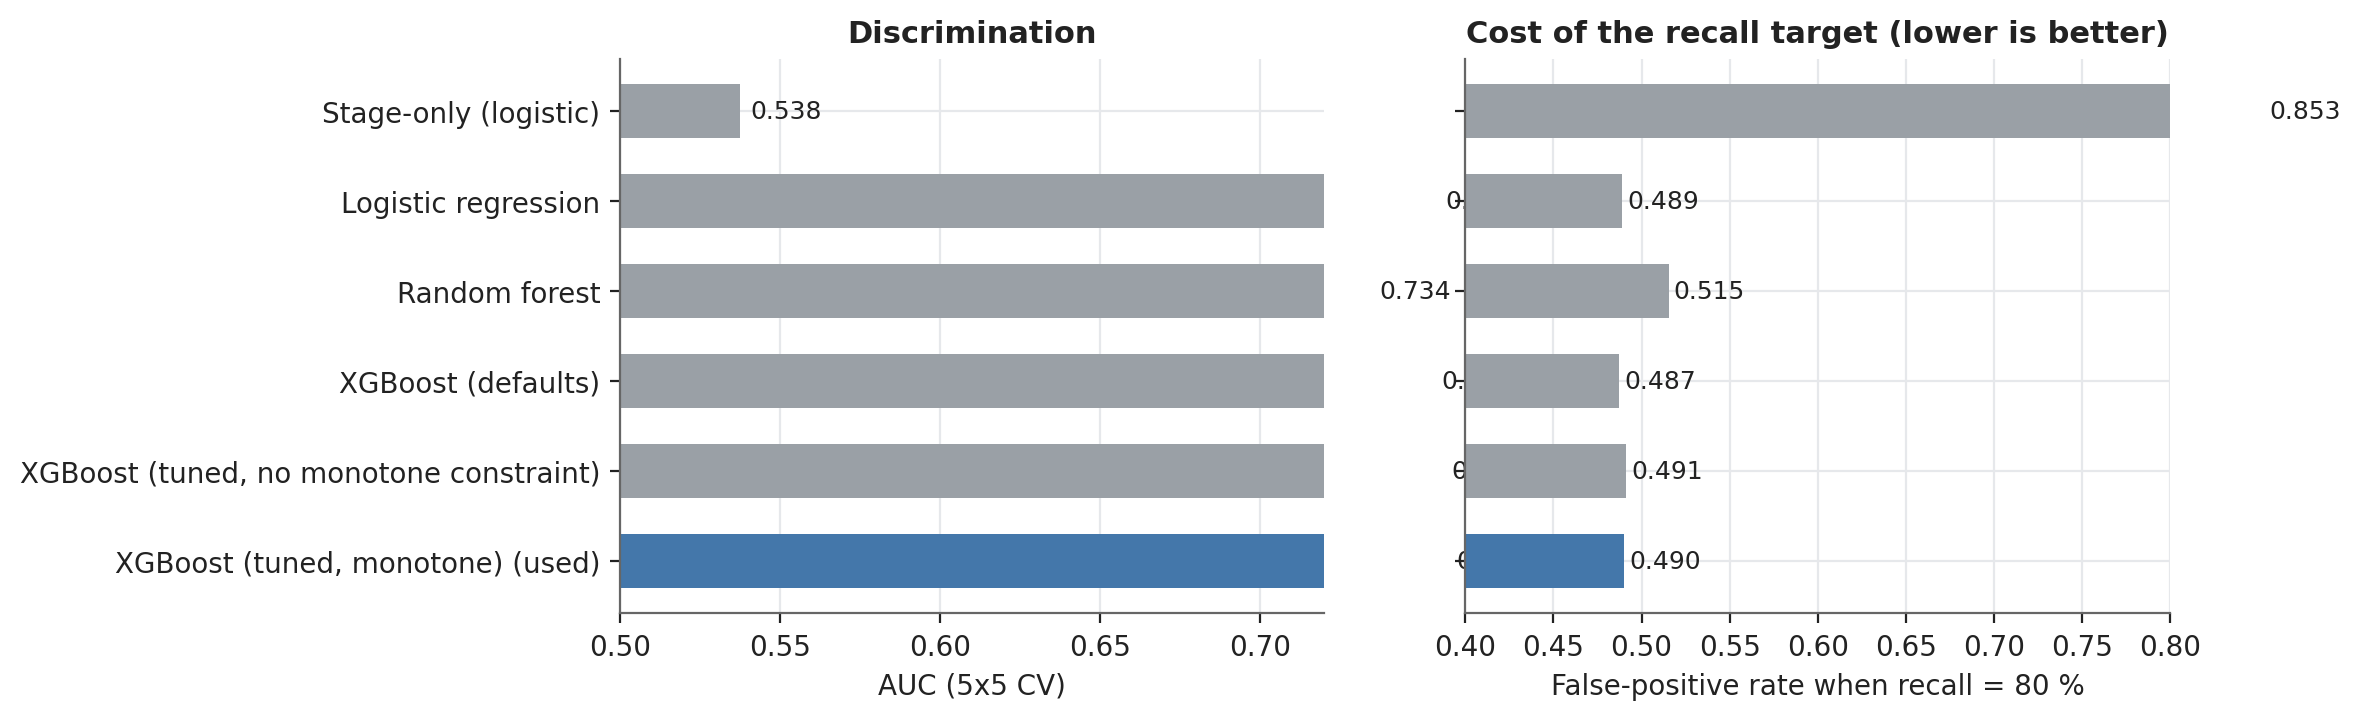

In [8]:
display(s.bench.round(3)); plots.fig_benchmark(s, s.fig); show("03_model_benchmark.png", 900)

## 4. Hold-out performance, baselines, recall-first threshold, overfitting (proposal 3.2.4-3.2.5)

In [9]:
s.holdout()
tm = s.test_metrics
pv = tm.assign(v=tm.apply(lambda r: f"{r.estimate:.3f}" + ("" if pd.isna(r.lo) else f" [{r.lo:.3f}, {r.hi:.3f}]"), axis=1)).pivot(index="model", columns="metric", values="v")
display(pv[["recall", "precision", "f1", "accuracy", "balanced_accuracy", "auc_roc", "pr_auc", "flag_rate"]])
say(f"Always predicting 'living' scores {1 - s.y[~s.dev].mean():.1%} accuracy - so accuracy is read against that; PR-AUC against the no-skill value {s.y[~s.dev].mean():.2f}.")
display(s.test_confusion)

[17:32:32] [proposal] hold-out evaluation ...


metric,recall,precision,f1,accuracy,balanced_accuracy,auc_roc,pr_auc,flag_rate
model,,,,,,,,
Always 'living' (no skill),NaN,NaN,NaN,0.862,NaN,NaN,NaN,NaN
Logistic regression,"0.700 [0.519, 0.853]","0.221 [0.143, 0.303]","0.336 [0.230, 0.435]","0.618 [0.548, 0.677]","0.652 [0.559, 0.734]","0.732 [0.604, 0.833]","0.477 [0.304, 0.652]","0.438 [0.369, 0.502]"
Random forest,"0.800 [0.652, 0.938]","0.220 [0.147, 0.297]","0.345 [0.246, 0.439]","0.581 [0.521, 0.650]","0.673 [0.585, 0.749]","0.769 [0.660, 0.865]","0.471 [0.297, 0.642]","0.502 [0.438, 0.571]"
Stage-only (logistic),"0.867 [0.733, 0.971]","0.155 [0.098, 0.208]","0.263 [0.175, 0.337]","0.327 [0.258, 0.387]","0.554 [0.478, 0.616]","0.616 [0.506, 0.712]","0.199 [0.122, 0.324]","0.774 [0.719, 0.829]"
"XGBoost (race-aware, primary)","0.700 [0.529, 0.846]","0.233 [0.148, 0.319]","0.350 [0.234, 0.452]","0.641 [0.576, 0.710]","0.666 [0.572, 0.753]","0.765 [0.660, 0.858]","0.471 [0.298, 0.663]","0.415 [0.346, 0.479]"
XGBoost (race-blind),"0.733 [0.555, 0.880]","0.202 [0.127, 0.275]","0.317 [0.208, 0.411]","0.562 [0.498, 0.627]","0.634 [0.543, 0.716]","0.756 [0.648, 0.851]","0.438 [0.291, 0.644]","0.502 [0.438, 0.567]"


Always predicting 'living' scores 86.2% accuracy - so accuracy is read against that; PR-AUC against the no-skill value 0.14.

,model,tp,fn,fp,tn,threshold
0,"XGBoost (race-aware, primary)",21,9,69,118,0.388518
1,XGBoost (race-blind),22,8,87,100,0.370433
2,Logistic regression,21,9,74,113,0.356105
3,Random forest,24,6,85,102,0.313800
4,Stage-only (logistic),26,4,142,45,0.487301


,rule,threshold,recall,precision,specificity,f1,flag_rate,dev_recall,dev_precision
0,recall >= 80 % (primary),0.389,0.700,0.233,0.631,0.350,0.415,0.802,0.234
1,recall >= 90 %,0.322,0.833,0.174,0.364,0.287,0.664,0.901,0.188
2,max recall s.t. precision >= 0.17,0.291,0.933,0.167,0.251,0.283,0.774,0.926,0.174
3,max F2,0.385,0.700,0.216,0.594,0.331,0.447,0.818,0.233
4,Youden J,0.496,0.600,0.383,0.845,0.468,0.217,0.595,0.343
5,0.5 (default),0.500,0.600,0.391,0.850,0.474,0.212,0.570,0.338


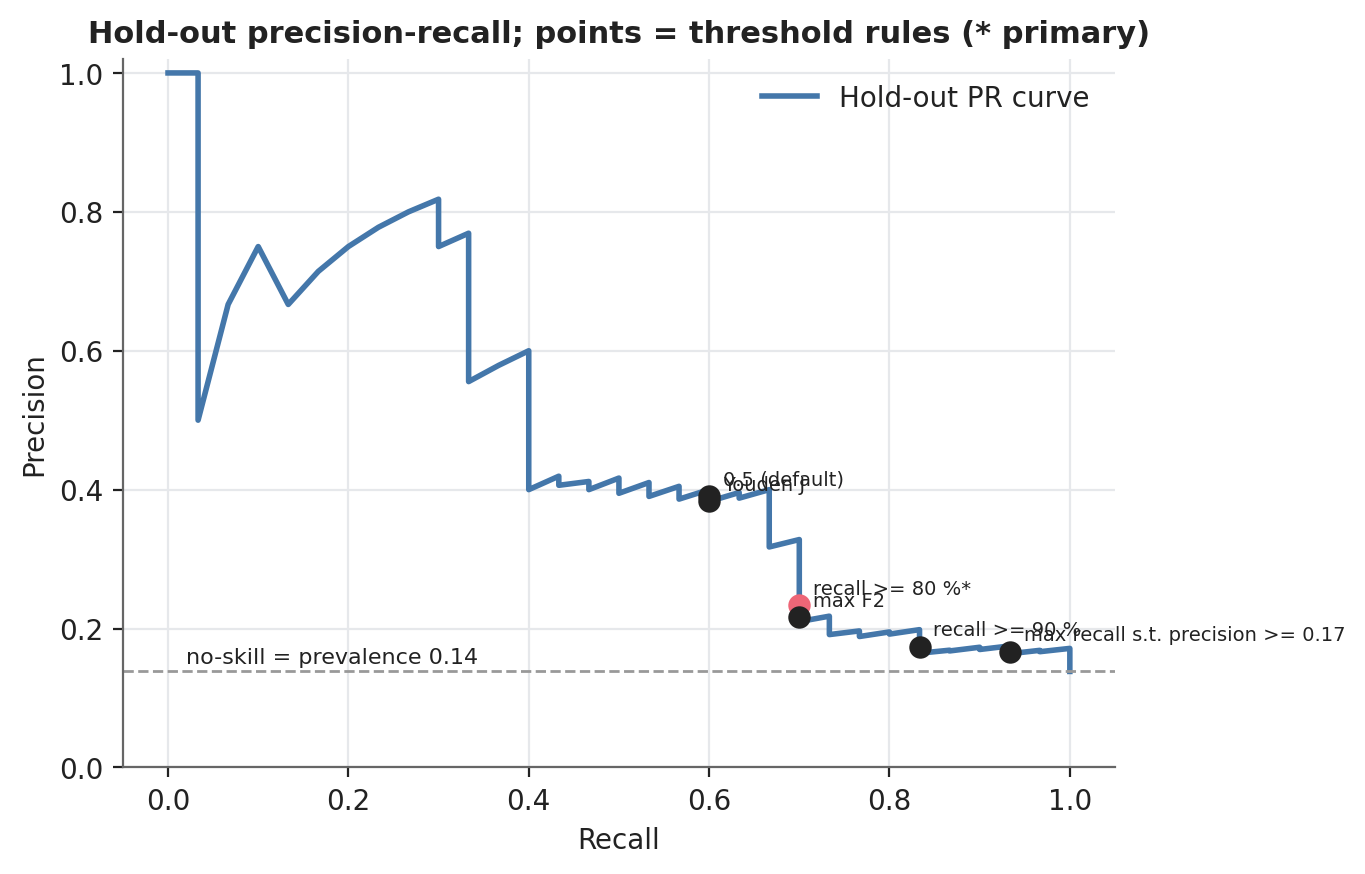

*The proposal asks to 'maximise recall at an acceptable precision'. Here that is operationalised as: catch >= 80 % of deaths, then check the precision floor (1.25 x prevalence). Any rule that ignores recall (Youden, F2, 0.5) gives up most deaths.*

In [10]:
display(s.rule_table.round(3))
plots.fig_pr(s, s.fig); show("22_precision_recall.png", 520)
say("*The proposal asks to 'maximise recall at an acceptable precision'. Here that is operationalised as: catch >= 80 % of deaths, then check the precision floor (1.25 x prevalence). "
    "Any rule that ignores recall (Youden, F2, 0.5) gives up most deaths.*")

,trees,train,cv,cv_sd,test
0,10,0.770,0.725,0.057,0.762
6,70,0.801,0.737,0.069,0.773
12,130,0.821,0.747,0.068,0.760
18,190,0.831,0.751,0.067,0.769
24,250,0.837,0.753,0.066,0.765


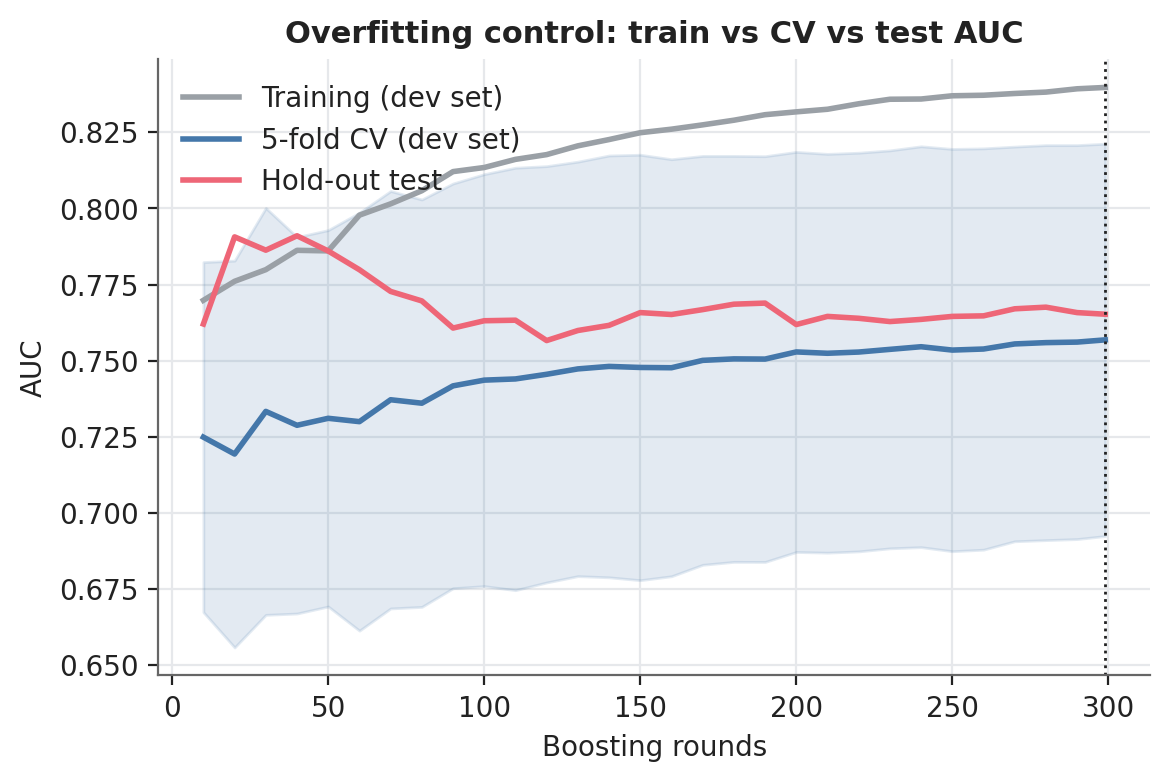

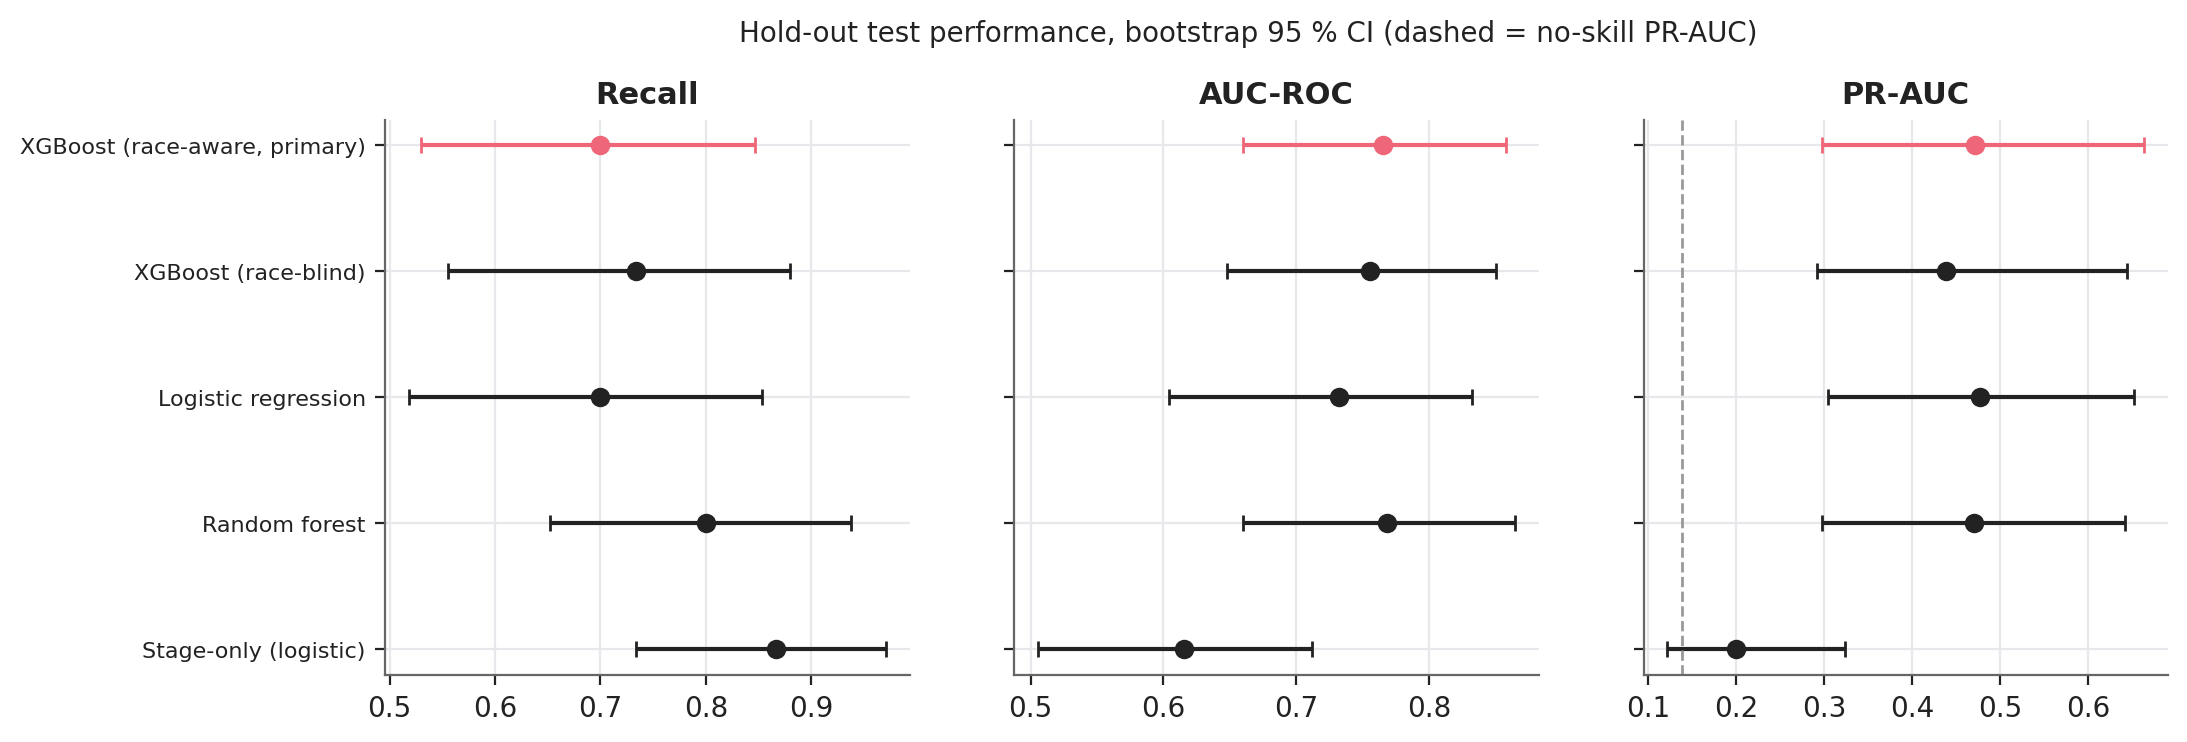

In [11]:
display(s.curve.iloc[::6].round(3)); plots.fig_learning_curve(s, s.fig); show("21_learning_curve.png", 520)
plots.fig_test_forest(s, s.fig); show("23_test_forest.png", 950)

## 5. SHAP explanations and their quality (proposal 3.2.6)

In [12]:
s.fairness(); s.sweep(); s.sensitivity(); s.final_models(); s.explain(); s.headline()
eq = s.res["explain_quality"]
say(f"**Fidelity**: max |base + sum(SHAP) - model margin| = {eq['fidelity']['max_abs_error']:.1e} over {eq['fidelity']['n']} patients. "
    f"**Stability**: mean Spearman across 10 CV-fold models {eq['fold_stability']['mean_spearman']:.2f} (min {eq['fold_stability']['min_spearman']:.2f}); across bootstraps {eq['bootstrap_stability']:.2f}. "
    f"**Agreement with XGBoost gain importance**: {eq['builtin']['gain']:.2f}.")
display(s.alignment); display(s.direction.round(3))

[17:33:40] [proposal] repeated 5x5-fold CV of all strategies ...


[17:33:57] bootstrap ...


[17:34:19] [proposal] recall-target sweep ...


[17:35:16] [proposal] sensitivity analyses ...


[17:35:18] [proposal] fitting deployment models on all patients ...


[17:35:23] [proposal] SHAP and explanation quality ...


[17:35:27] SHAP stability bootstrap ...


**Fidelity**: max |base + sum(SHAP) - model margin| = 2.4e-06 over 1084 patients. **Stability**: mean Spearman across 10 CV-fold models 0.90 (min 0.79); across bootstraps 0.82. **Agreement with XGBoost gain importance**: 0.95.

,rank,feature,mean_abs_shap,established_prognostic_factor
0,1,Radiation therapy,0.334693,no (administrative / treatment-documentation field)
1,2,Nodal status (N),0.299000,Nodal status
2,3,Age at diagnosis,0.231253,Age at diagnosis
3,4,Race: Asian,0.151737,no (administrative / treatment-documentation field)
4,5,Distant metastasis (M),0.125959,Metastasis


,feature,expected,spearman,agrees,mean_abs_shap
0,Age at diagnosis,higher -> more risk,0.646,True,0.231
1,Tumour size (T),higher -> more risk,0.854,True,0.116
2,Nodal status (N),higher -> more risk,0.921,True,0.299
3,Distant metastasis (M),higher -> more risk,0.259,True,0.126


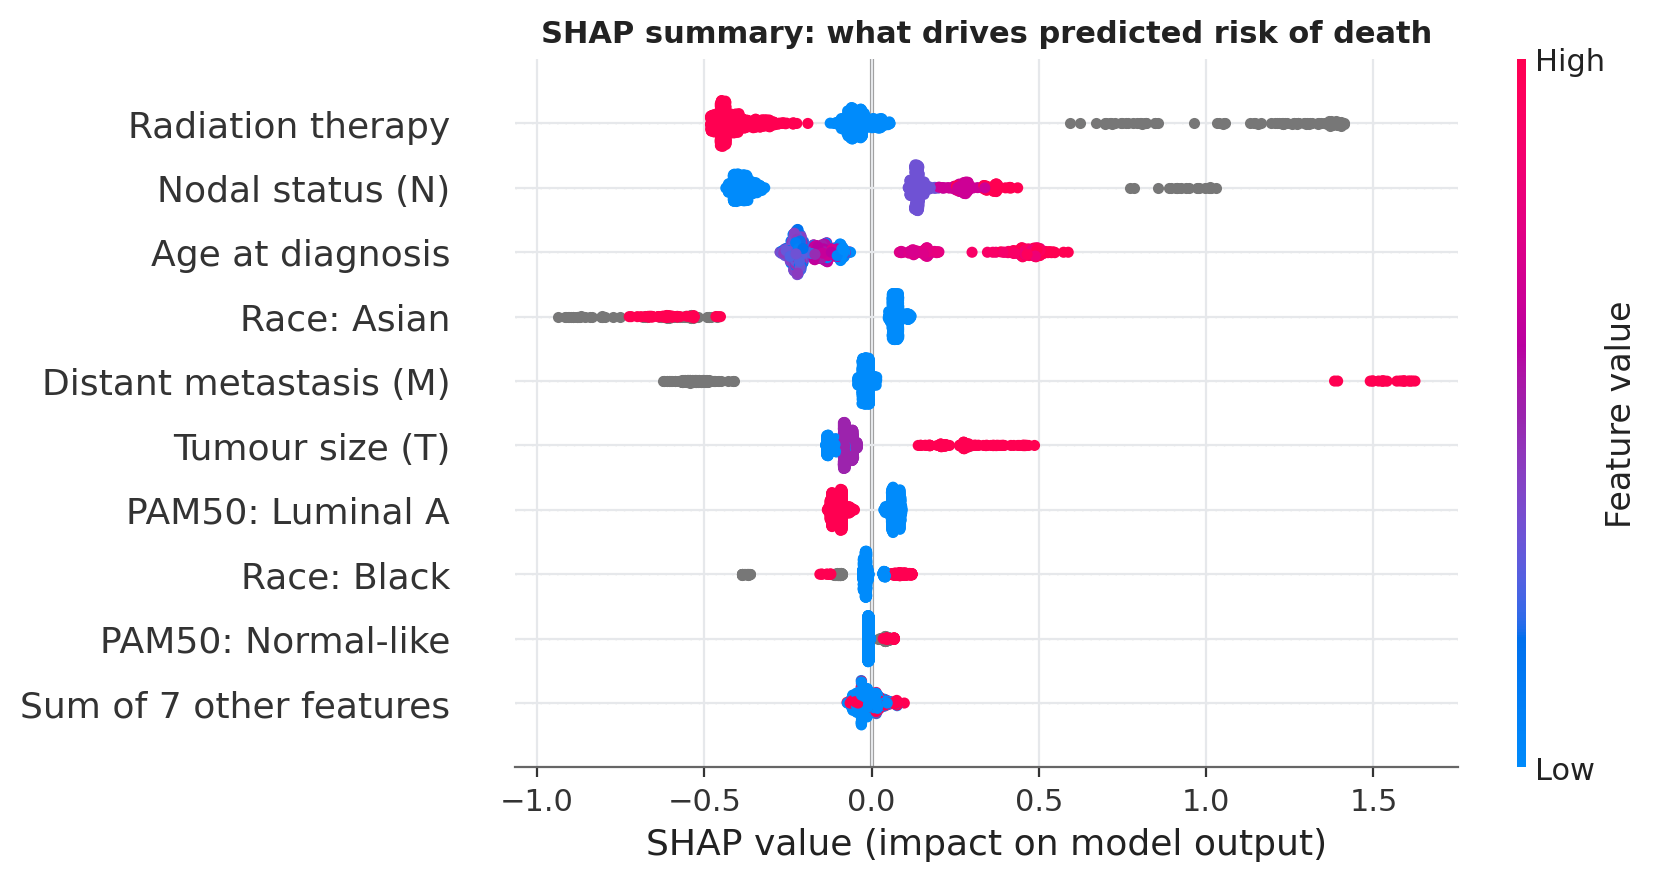

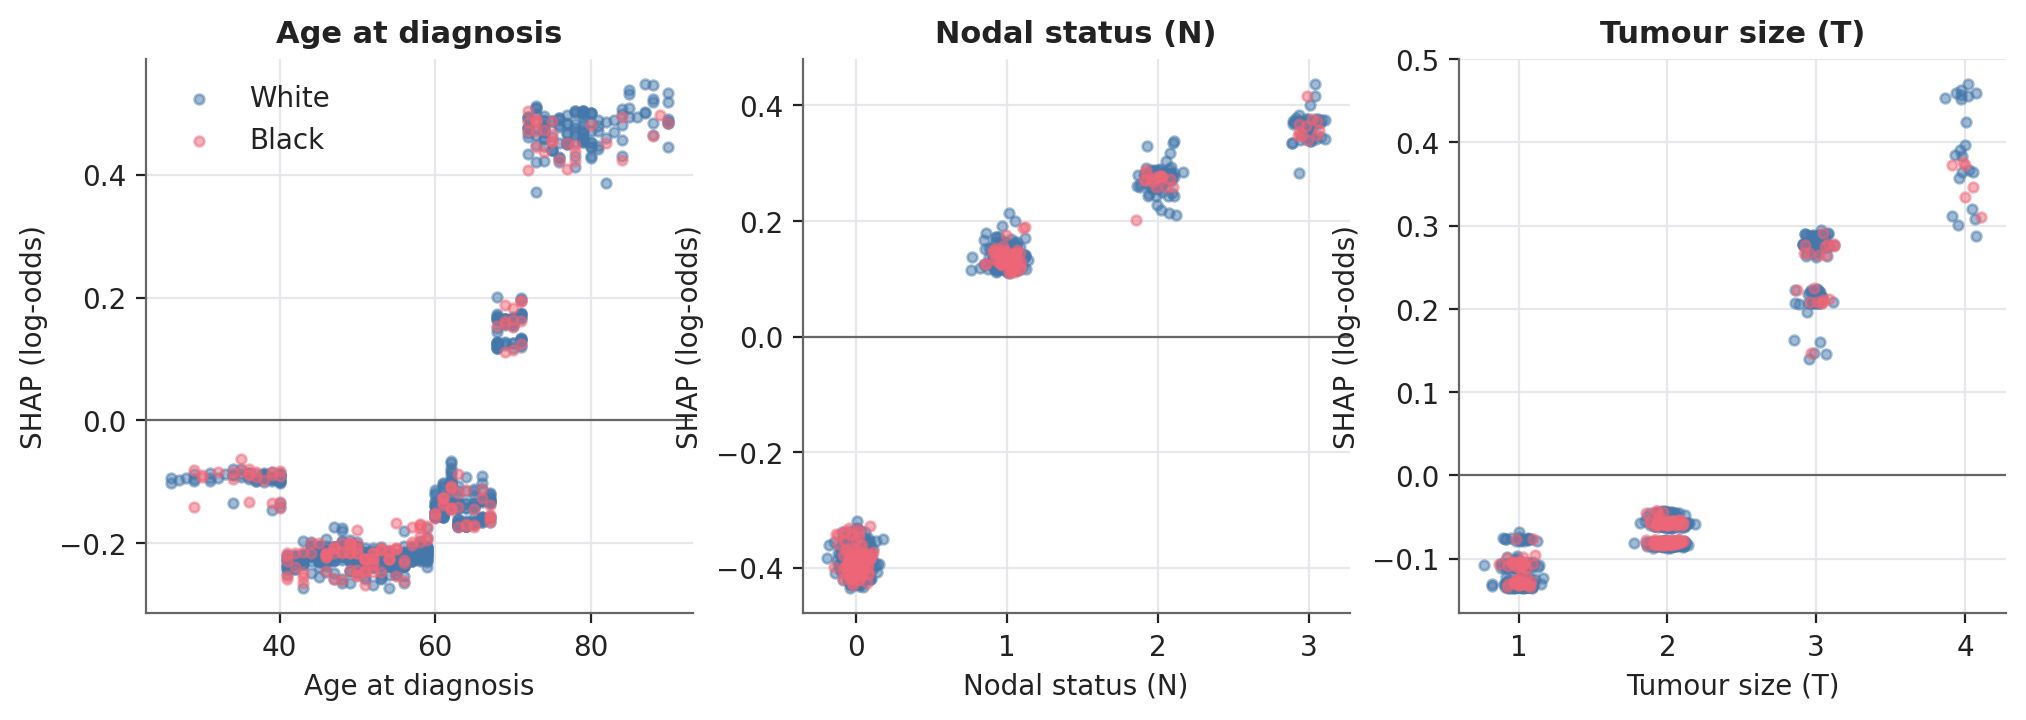

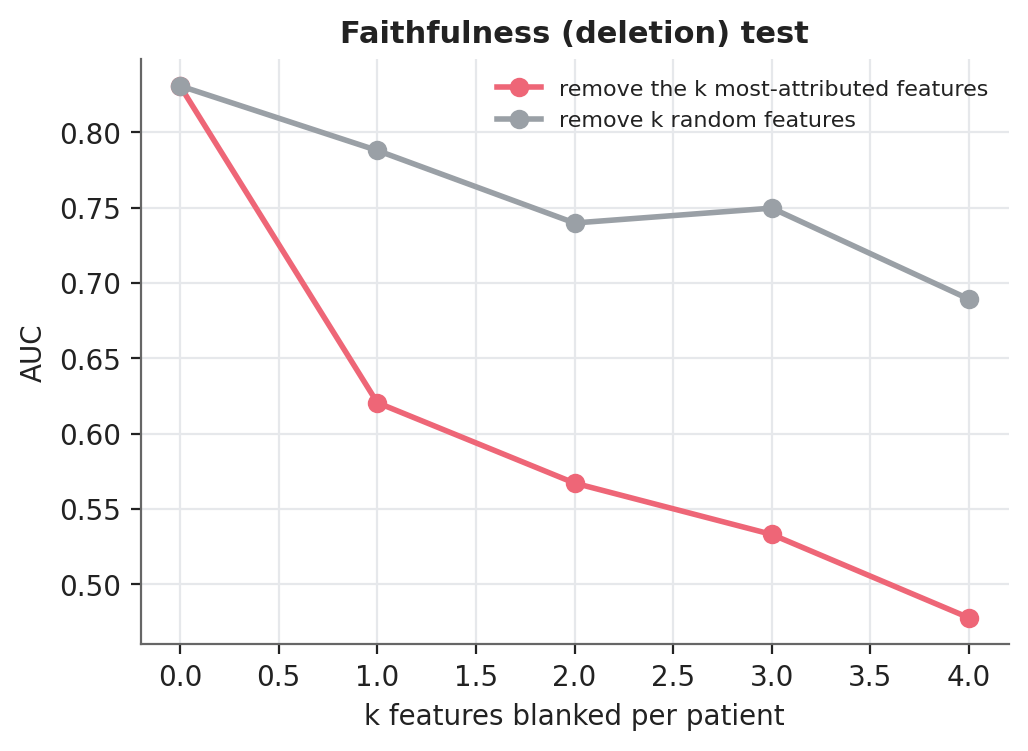

In [13]:
plots.fig_shap_global(s, s.fig); show("12_shap_beeswarm.png", 700)
plots.fig_dependence(s, s.fig); show("14_dependence.png", 1000)
plots.fig_deletion(s, s.fig); show("26_deletion_test.png", 450)

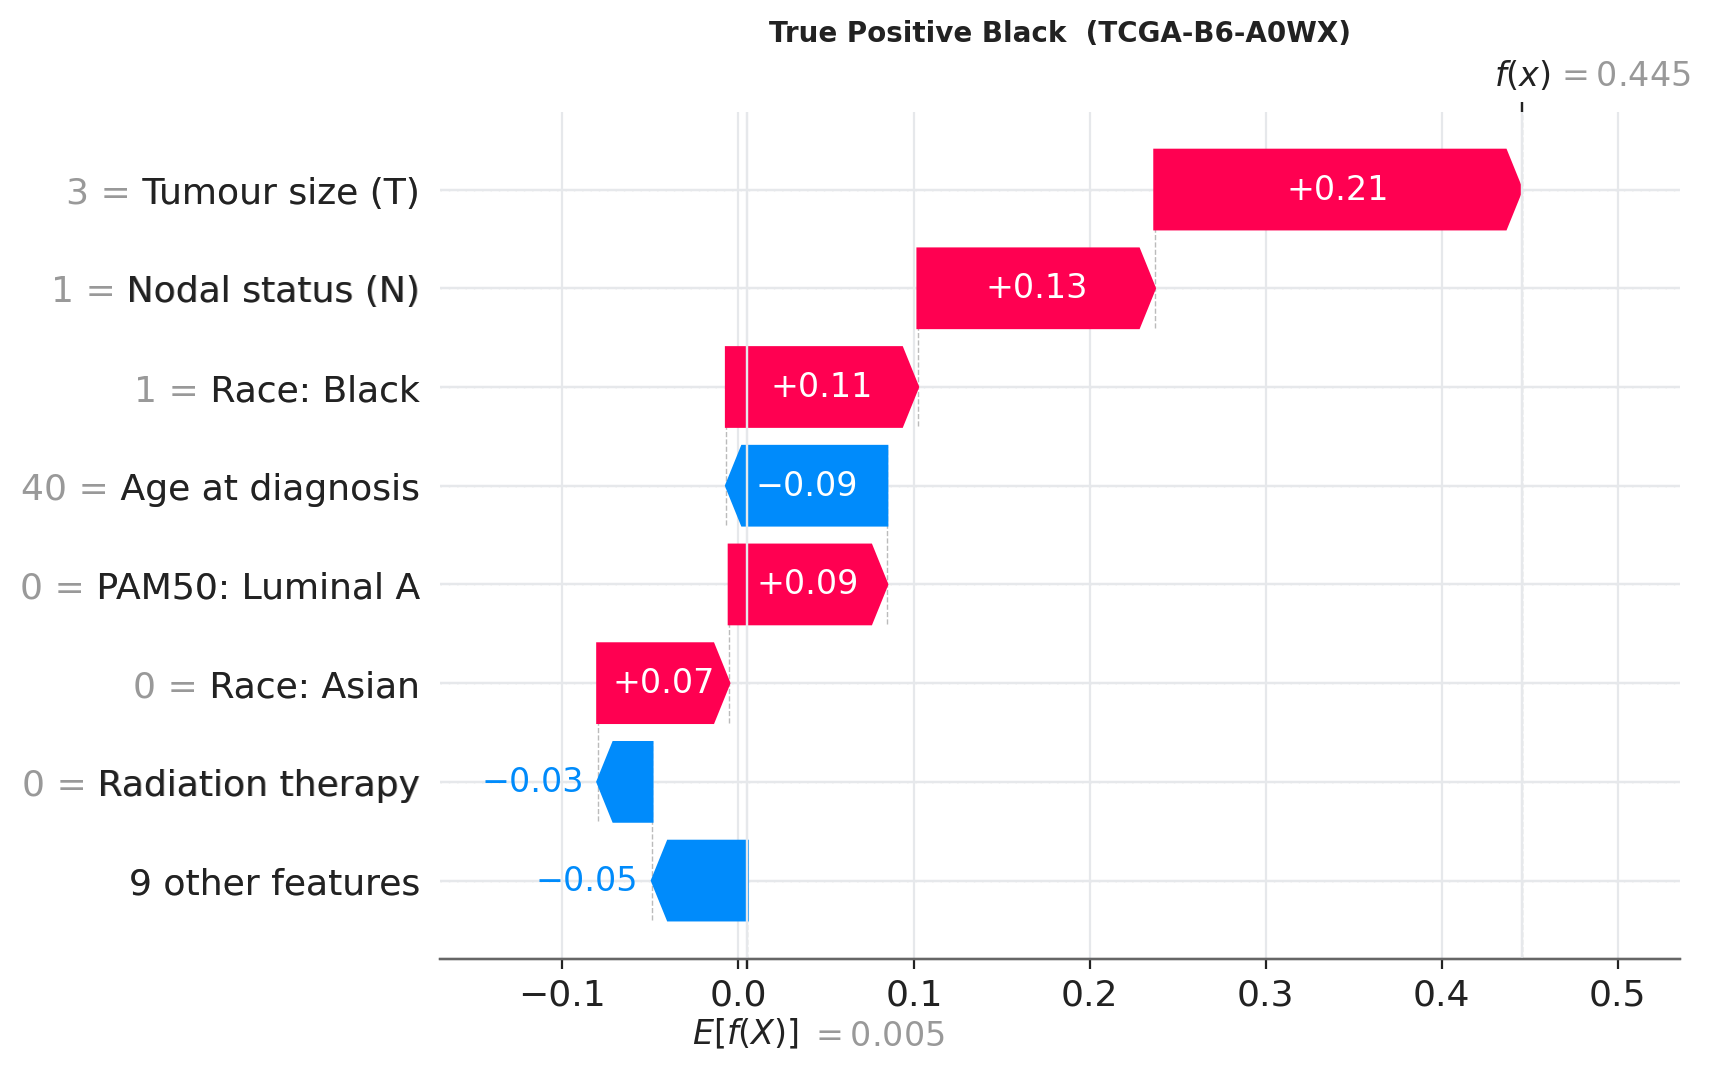

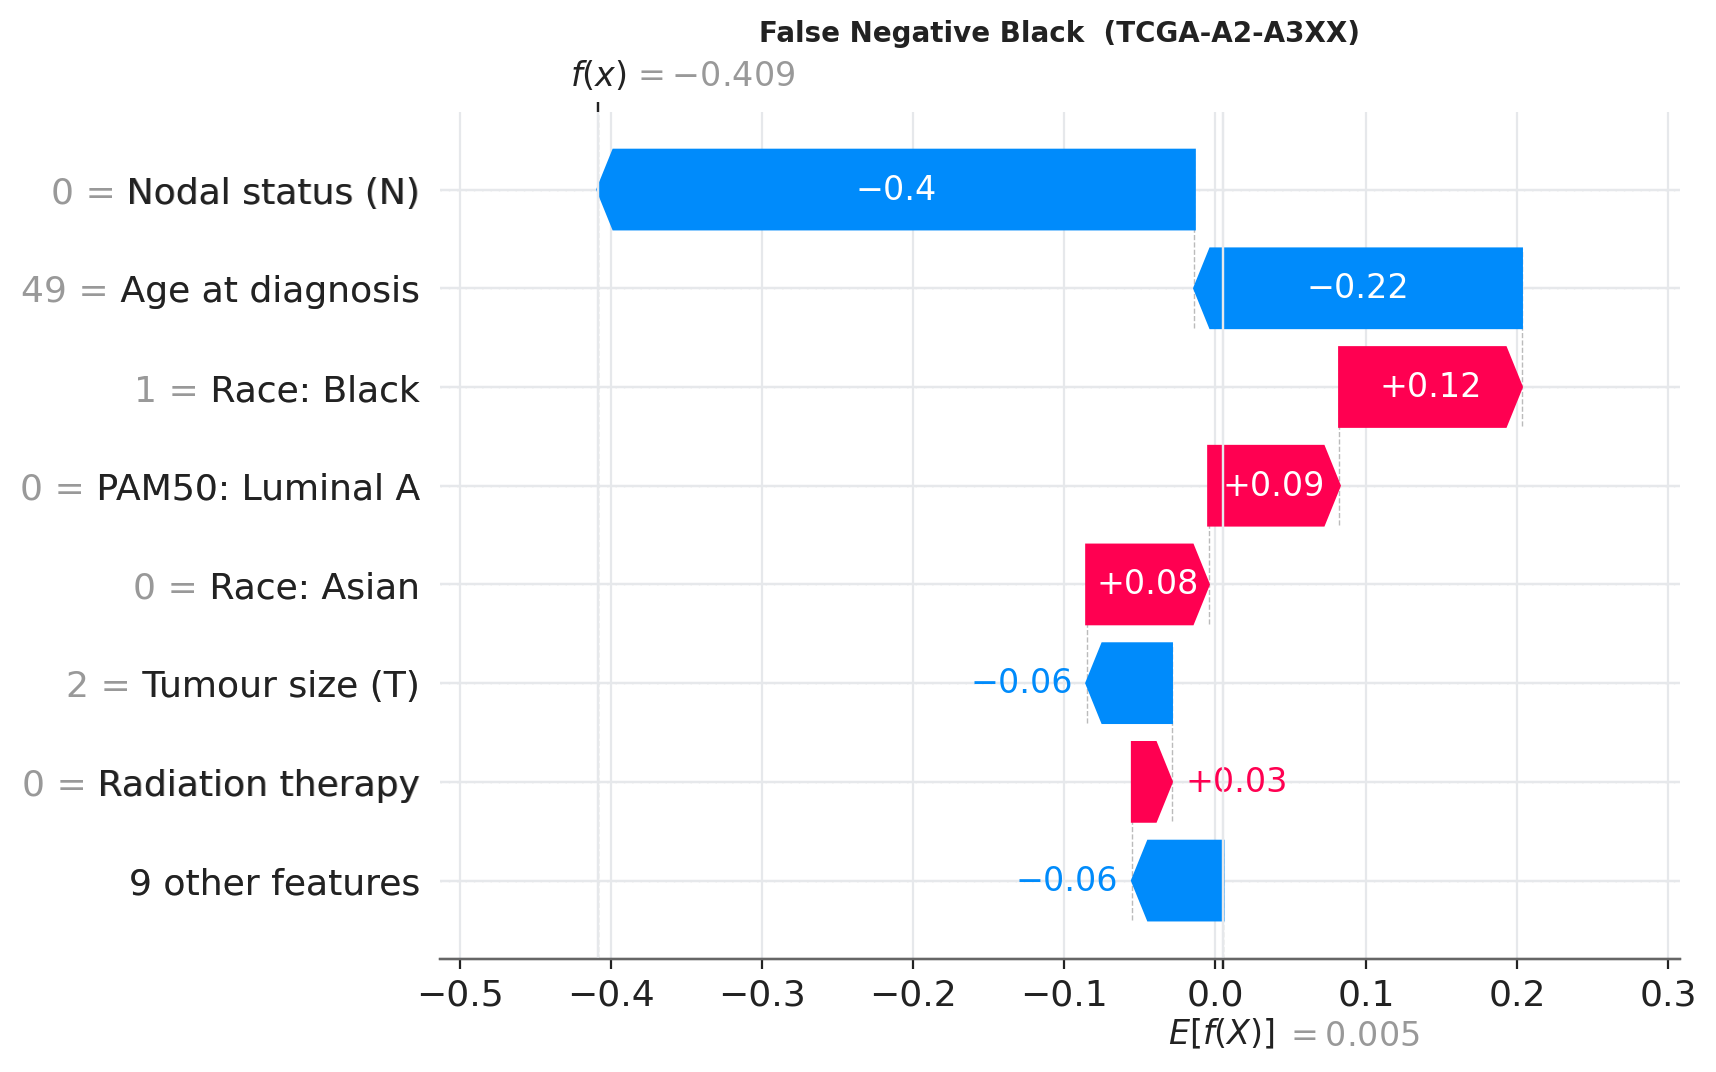

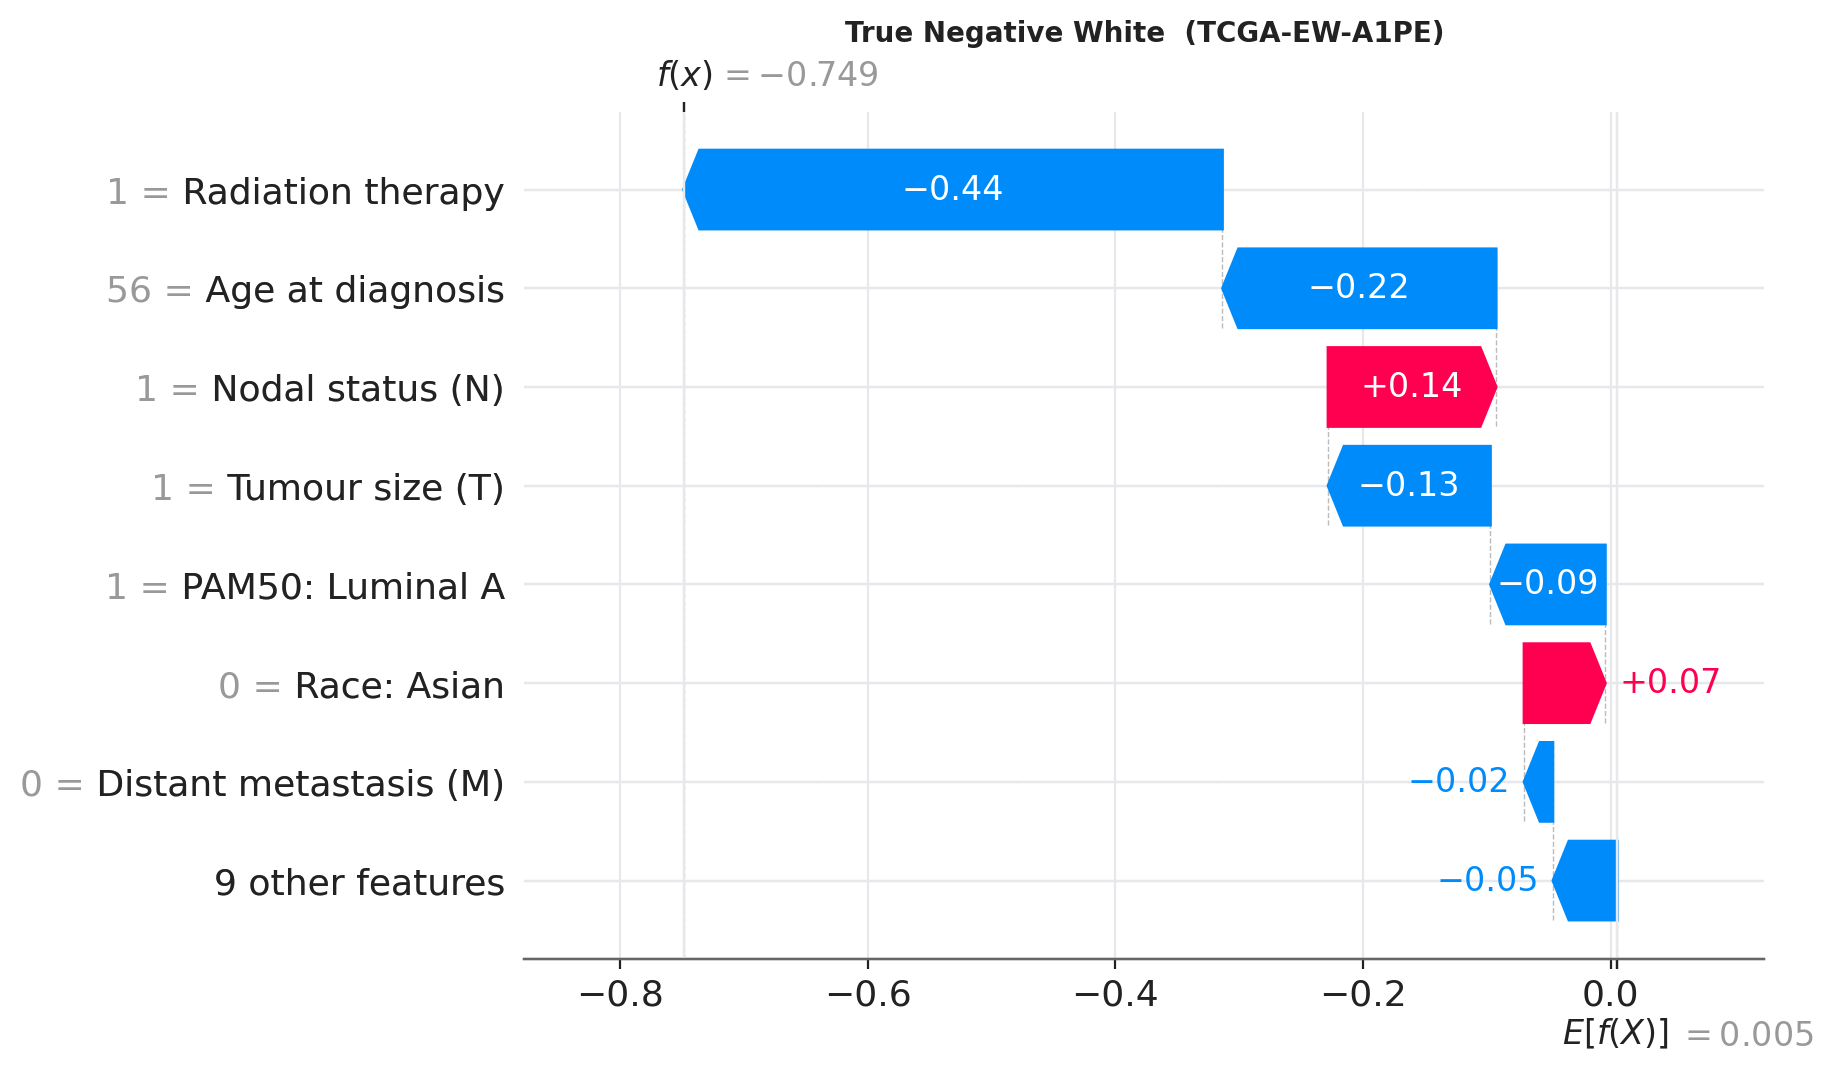

In [14]:
plots.fig_waterfalls(s, s.fig)
for n in ["true_positive_black", "false_negative_black", "true_negative_white"]:
    show(f"15_waterfall_{n}.png", 520)

**Race check (proposal 3.2.6 'fairness check').** Mean attribution of the race columns, by whether race was recorded:

,patients,n,mean_race_shap,mean_abs_race_shap,share_of_total_attribution,death_rate
0,race recorded,993,0.036,0.112,0.081,0.145
1,race NOT recorded,91,-0.827,0.827,0.393,0.077


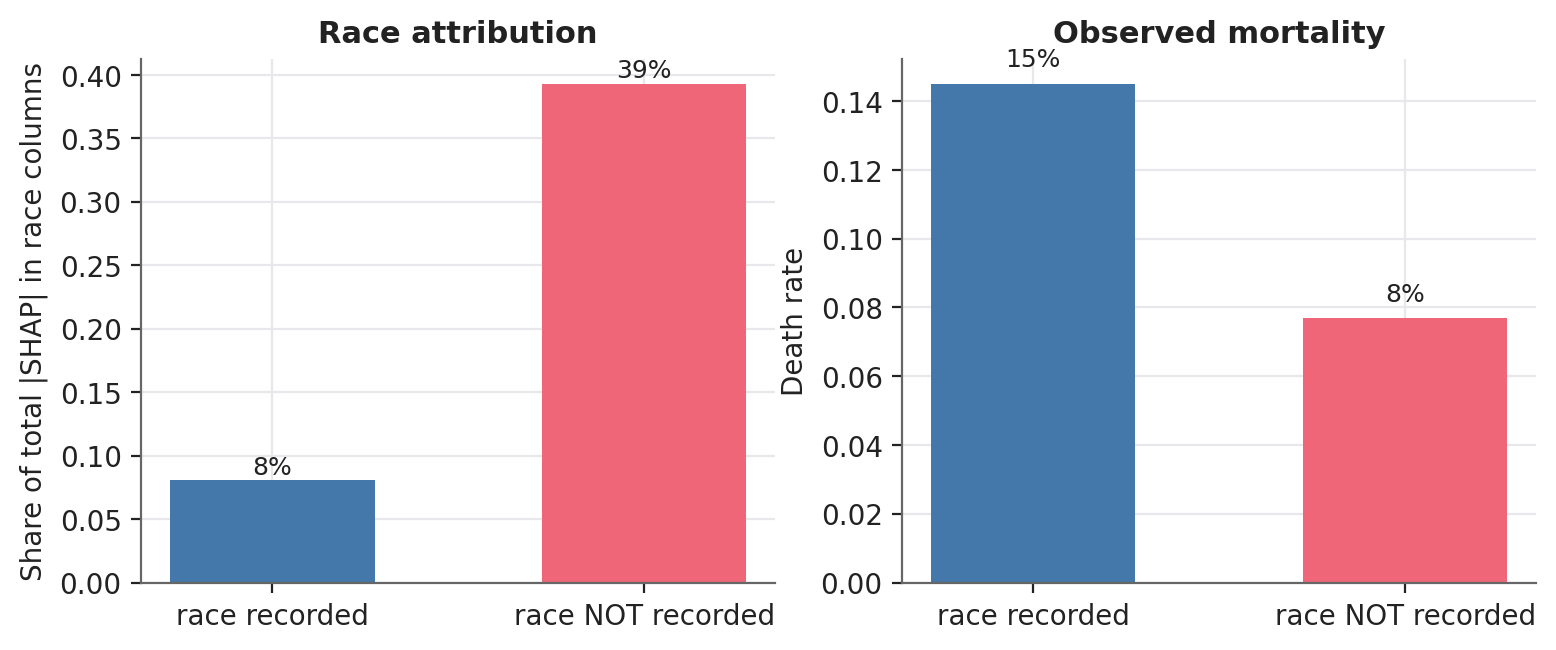

In [15]:
say("**Race check (proposal 3.2.6 'fairness check').** Mean attribution of the race columns, by whether race was recorded:")
display(s.race_shap.round(3)); plots.fig_race_missing(s, s.fig); show("25_race_missing_signal.png", 700)

## 6. Fairness audit and mitigation (extension)

5 strategies x 5 repeats x 5-fold CV on all patients; fairness metrics on the White and Black patients. Gap = Black minus White.
Recall gap = equal opportunity (0 is fair); false-alarm gap > 0 means Black survivors are flagged more often.

metric,eod,flag_all,fpr_B,fpr_W,fpr_gap,tpr_B,tpr_W,tpr_gap
strategy,,,,,,,,
aware,"0.072 [0.017, 0.170]","0.584 [0.558, 0.613]","0.554 [0.484, 0.622]","0.540 [0.507, 0.574]","0.014 [-0.066, 0.089]","0.873 [0.786, 0.946]","0.802 [0.738, 0.863]","0.072 [-0.042, 0.170]"
blind,"0.077 [0.032, 0.225]","0.565 [0.538, 0.594]","0.467 [0.394, 0.539]","0.539 [0.504, 0.572]","-0.072 [-0.154, 0.007]","0.727 [0.588, 0.850]","0.804 [0.739, 0.864]","-0.077 [-0.225, 0.065]"
reweigh,"0.109 [0.052, 0.264]","0.572 [0.545, 0.600]","0.457 [0.384, 0.530]","0.553 [0.519, 0.585]","-0.096 [-0.178, -0.016]","0.700 [0.556, 0.839]","0.809 [0.743, 0.870]","-0.109 [-0.264, 0.048]"
gthr,"0.039 [0.013, 0.158]","0.572 [0.545, 0.601]","0.501 [0.427, 0.575]","0.540 [0.506, 0.573]","-0.039 [-0.124, 0.038]","0.780 [0.661, 0.886]","0.798 [0.735, 0.858]","-0.018 [-0.153, 0.108]"
reweigh_gthr,"0.022 [0.013, 0.149]","0.570 [0.544, 0.598]","0.512 [0.438, 0.584]","0.534 [0.501, 0.566]","-0.022 [-0.103, 0.056]","0.787 [0.673, 0.894]","0.802 [0.737, 0.863]","-0.015 [-0.140, 0.117]"


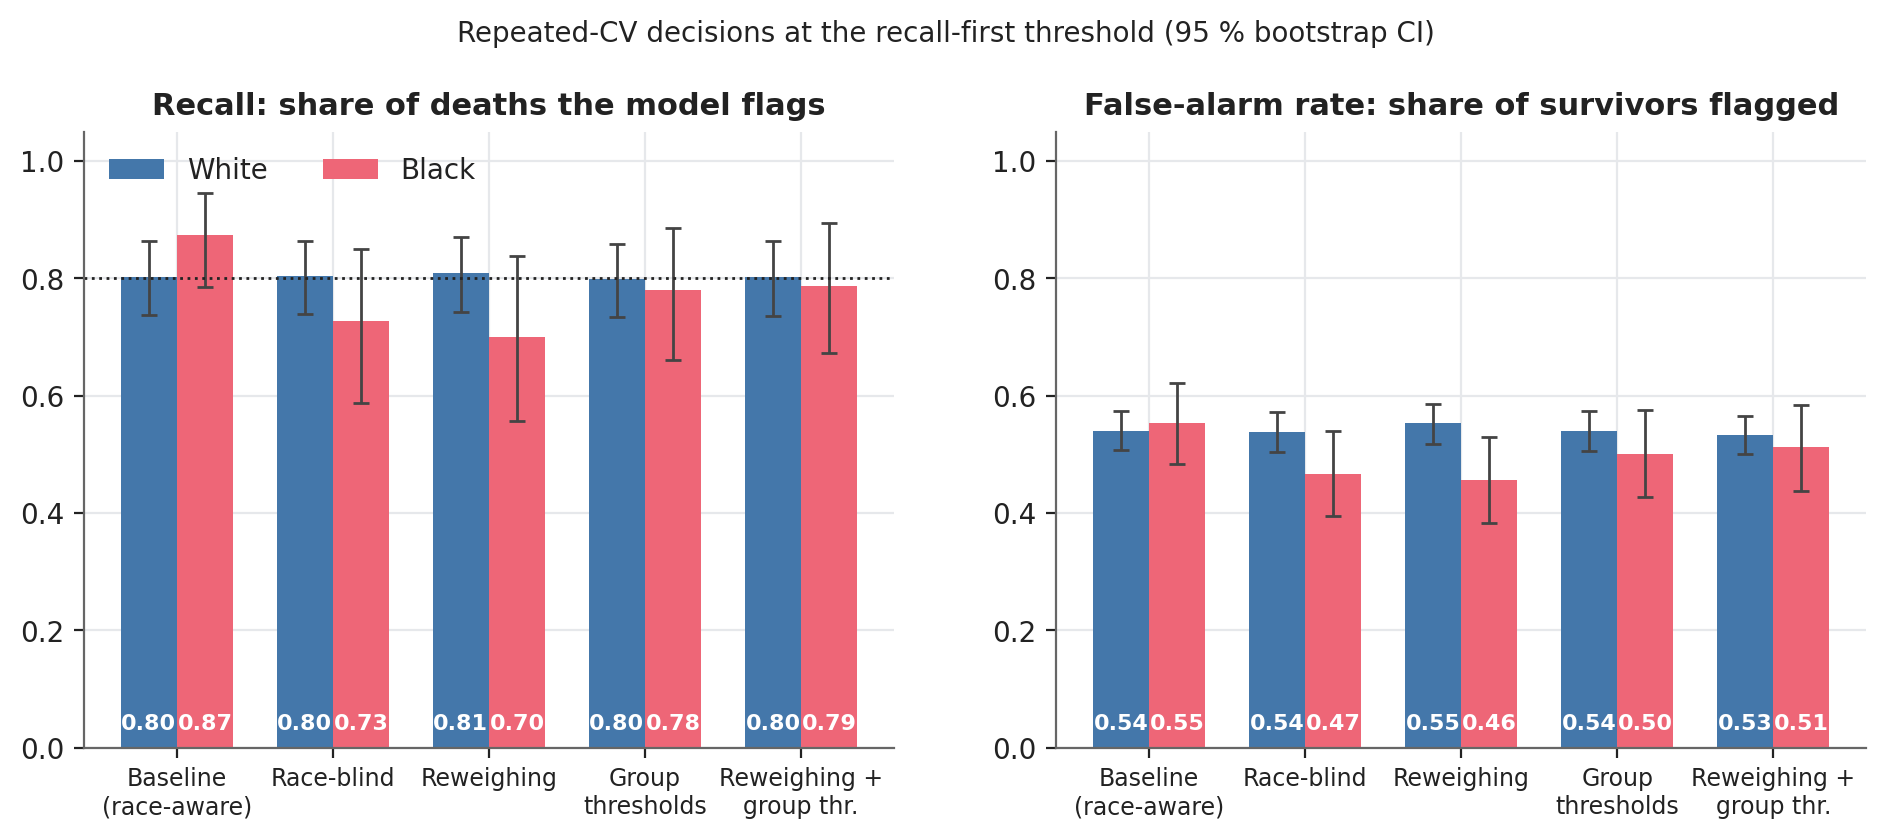

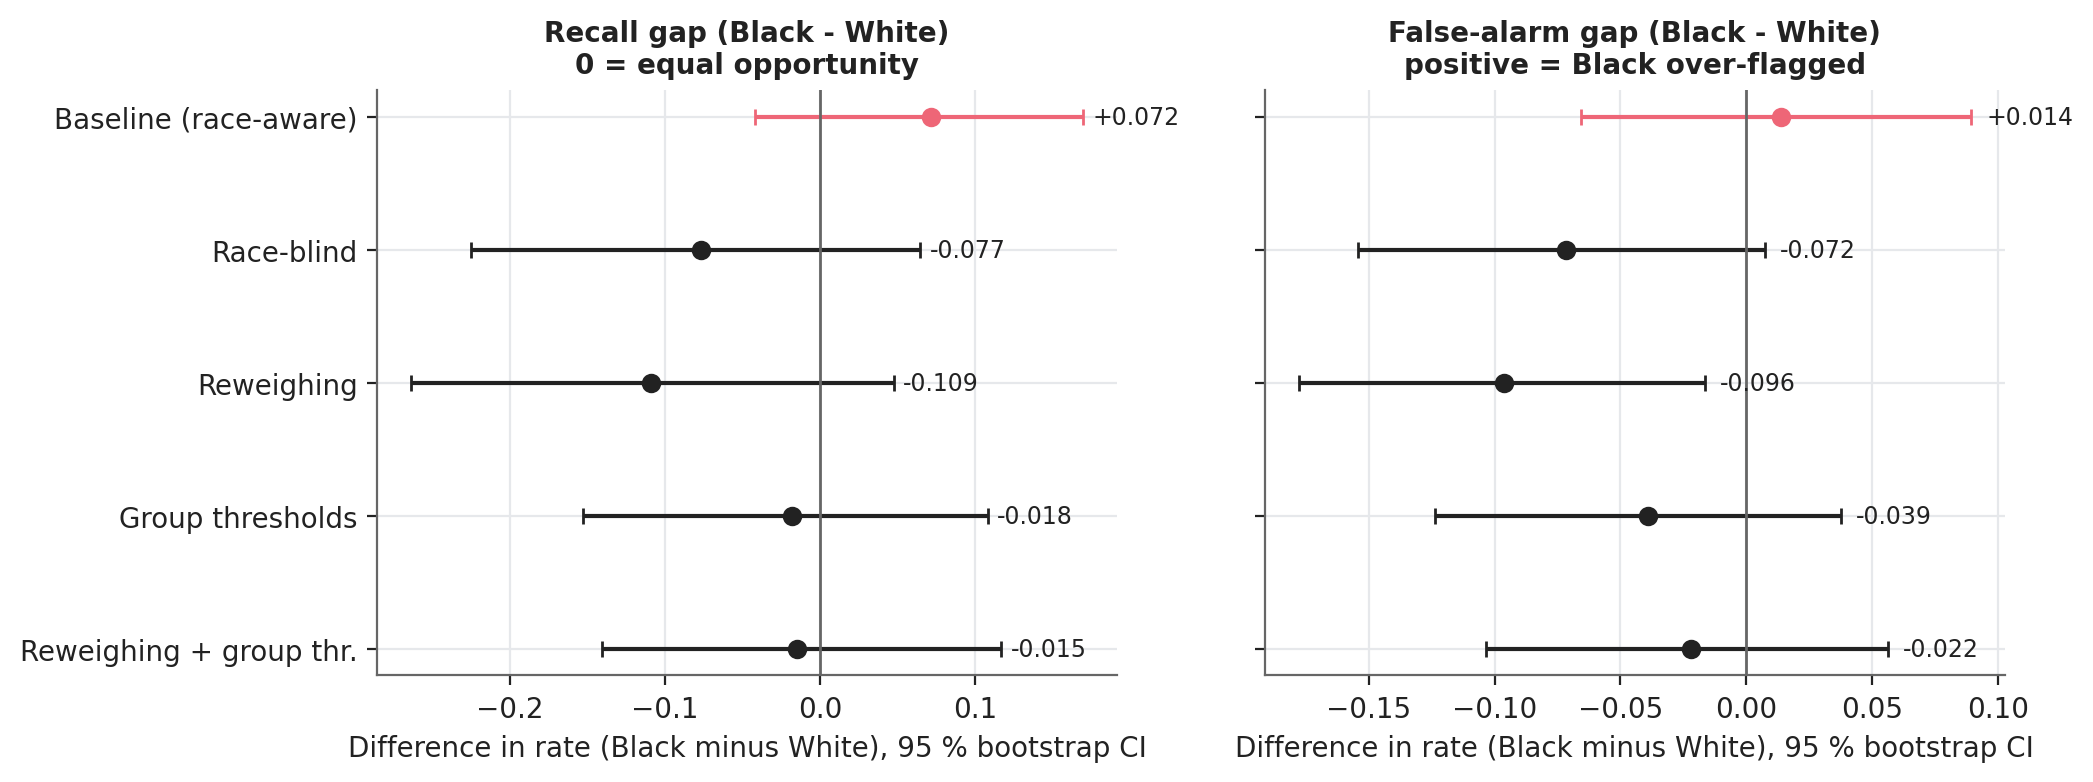

In [16]:
t = s.summary[s.summary.metric.isin(["tpr_W", "tpr_B", "tpr_gap", "fpr_W", "fpr_B", "fpr_gap", "eod", "flag_all"])]
t = t.assign(v=t.apply(lambda r: f"{r.estimate:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)).pivot(index="strategy", columns="metric", values="v")
display(t.loc[[x.key for x in s.strategies]])
plots.fig_group_rates(s, s.fig); show("05_rates_by_race.png", 1000); plots.fig_gaps(s, s.fig); show("06_gap_forest.png", 1000)

,strategy,metric,diff_vs_aware,lo,hi,prob_smaller
0,blind,tpr_gap,-0.147,-0.236,-0.064,1.000
1,blind,fpr_gap,-0.085,-0.111,-0.060,1.000
2,blind,abs_tpr_gap,0.009,-0.141,0.192,0.501
3,blind,eod,0.027,-0.100,0.183,0.393
4,reweigh,tpr_gap,-0.179,-0.272,-0.091,1.000
5,reweigh,fpr_gap,-0.110,-0.140,-0.082,1.000
6,reweigh,abs_tpr_gap,0.036,-0.141,0.233,0.392
7,reweigh,eod,0.056,-0.086,0.224,0.260
8,gthr,tpr_gap,-0.088,-0.161,-0.024,0.999
9,gthr,fpr_gap,-0.053,-0.077,-0.032,1.000


**Baseline:** recall gap +0.072 (95% CI -0.042 to +0.170); false-alarm gap +0.014 (CI -0.066 to +0.089). With 30 Black deaths the recall CI is about +-0.11: a gap of that size cannot be excluded.

,group,strategy,auc,lo,hi
0,All,aware,0.751,0.705,0.796
1,White,aware,0.757,0.706,0.814
2,Black,aware,0.718,0.621,0.805
3,All,blind,0.746,0.700,0.791
4,White,blind,0.758,0.707,0.814
5,Black,blind,0.717,0.625,0.807
6,All,reweigh,0.745,0.699,0.791
7,White,reweigh,0.760,0.708,0.814
8,Black,reweigh,0.712,0.616,0.805


,strategy,group,observed,mean_recalibrated,oe_ratio,raw_mean_score,within_group_slope,within_group_intercept,brier_recalibrated
0,aware,White,0.148,0.149,0.994,0.422,1.445,-1.660,0.096
1,aware,Black,0.165,0.146,1.126,0.424,1.019,-1.470,0.128
2,blind,White,0.148,0.133,1.110,0.408,1.550,-1.528,0.100
3,blind,Black,0.165,0.124,1.331,0.384,0.930,-1.317,0.129


,strategy,threshold,mean,sd,min,max
0,aware,global,0.361,0.013,0.328,0.381
1,aware,White,0.361,0.014,0.342,0.395
2,aware,Black,0.379,0.023,0.324,0.418
3,blind,global,0.351,0.012,0.320,0.378
4,blind,White,0.352,0.014,0.333,0.383
5,blind,Black,0.335,0.023,0.284,0.381
6,reweigh,global,0.341,0.013,0.313,0.381
7,reweigh,White,0.344,0.018,0.315,0.392
8,reweigh,Black,0.318,0.024,0.251,0.368
9,gthr,global,0.351,0.012,0.320,0.378


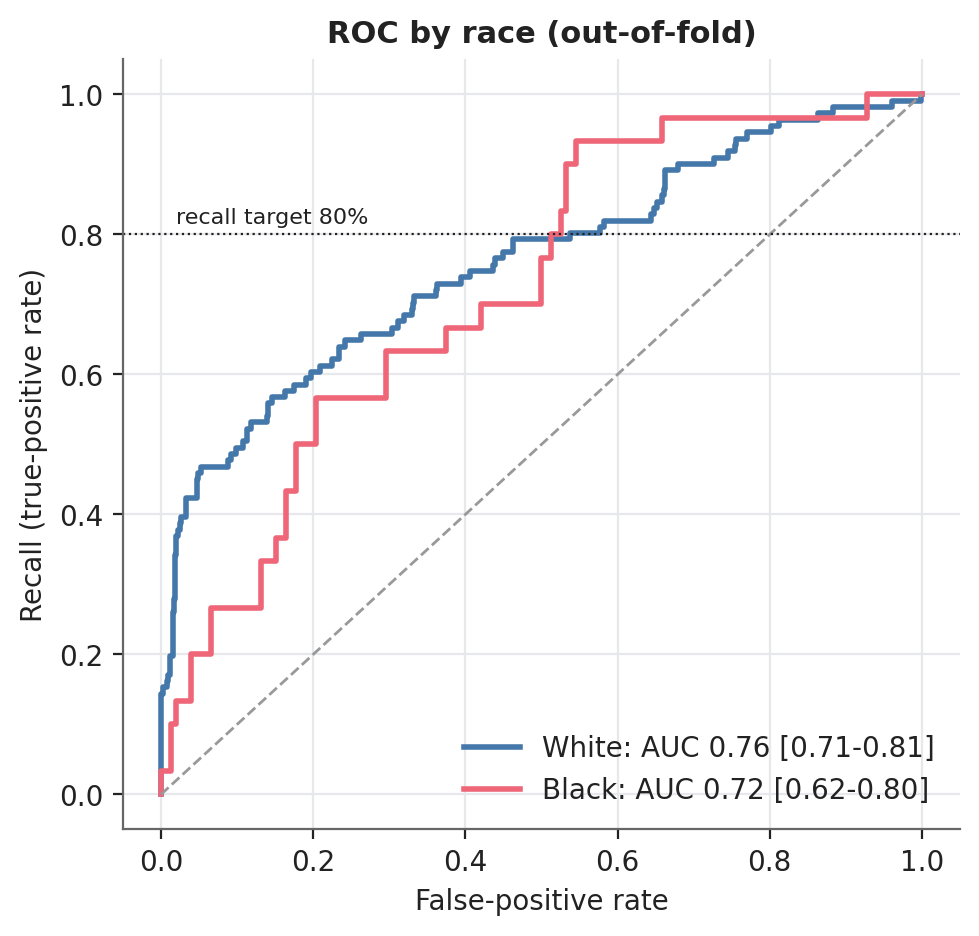

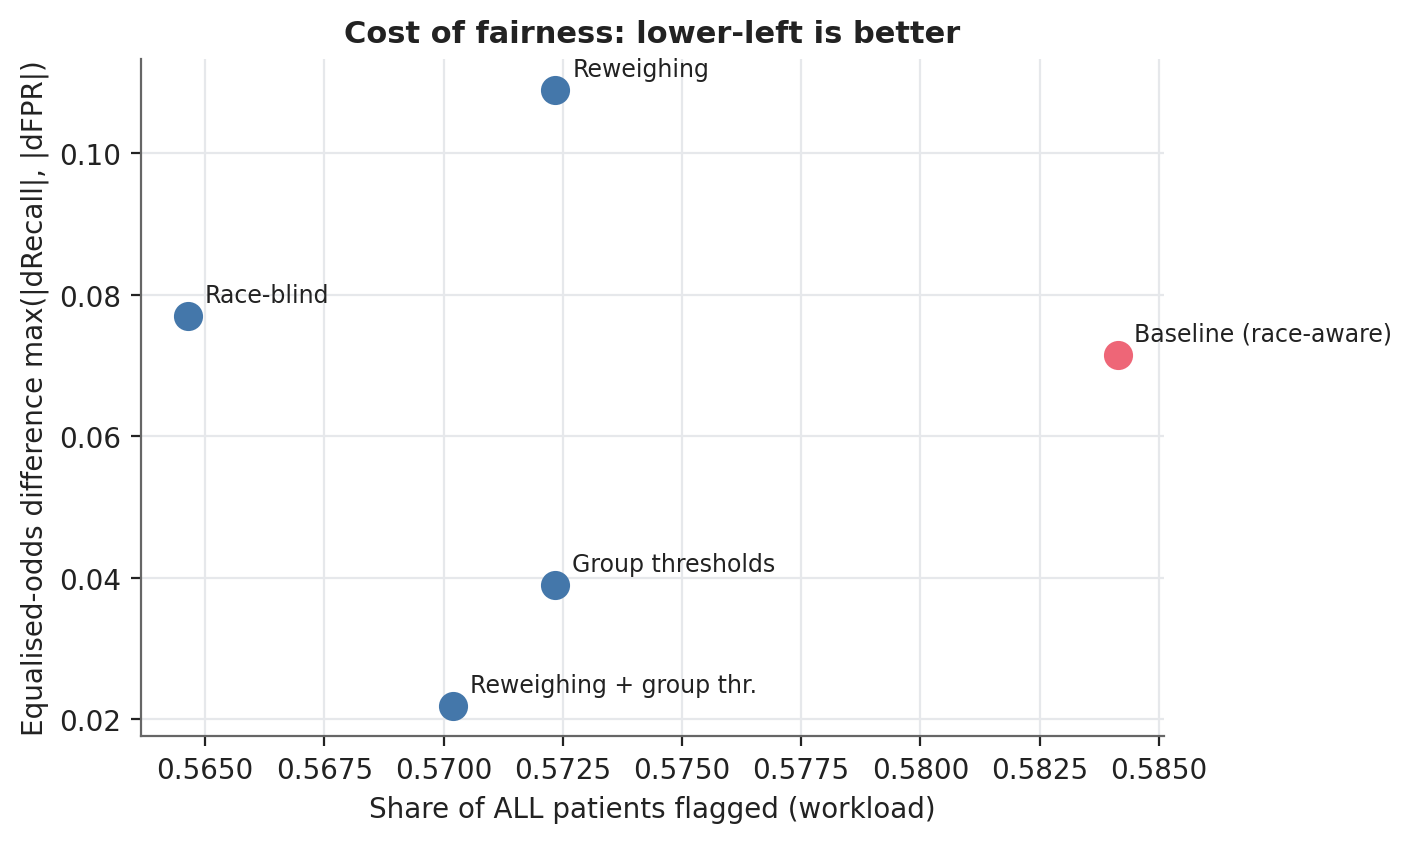

In [17]:
display(s.paired.round(3))
r = s.res["cv"]["aware"]
say(f"**Baseline:** recall gap {r['tpr_gap']:+.3f} (95% CI {r['tpr_gap_ci'][0]:+.3f} to {r['tpr_gap_ci'][1]:+.3f}); false-alarm gap {r['fpr_gap']:+.3f} (CI {r['fpr_gap_ci'][0]:+.3f} to {r['fpr_gap_ci'][1]:+.3f}). "
    f"With {s.res['flow']['deaths_black']} Black deaths the recall CI is about +-{(r['tpr_gap_ci'][1]-r['tpr_gap_ci'][0])/2:.2f}: a gap of that size cannot be excluded.")
display(s.auc_group.round(3)); display(s.calibration.round(3)); display(s.cv_thresholds.round(3))
plots.fig_roc(s, s.fig); show("04_roc_by_group.png", 450); plots.fig_tradeoff(s, s.fig); show("07_tradeoff.png", 550)

,White,Black,ratio_B_over_W,rank_White,rank_Black,label
radiation,0.355,0.286,0.805,1,2,Radiation therapy
n_stage,0.299,0.311,1.039,2,1,Nodal status (N)
age,0.230,0.223,0.971,3,4,Age at diagnosis
t_stage,0.117,0.112,0.960,4,5,Tumour size (T)
m_stage,0.107,0.233,2.178,5,3,Distant metastasis (M)
sub_luma,0.088,0.084,0.957,6,7,PAM50: Luminal A
race_asian,0.074,0.074,1.002,7,8,Race: Asian
race_black,0.020,0.092,4.603,8,6,Race: Black
sub_normal,0.013,0.015,1.157,9,9,PAM50: Normal-like
sub_lumb,0.011,0.011,0.992,10,10,PAM50: Luminal B


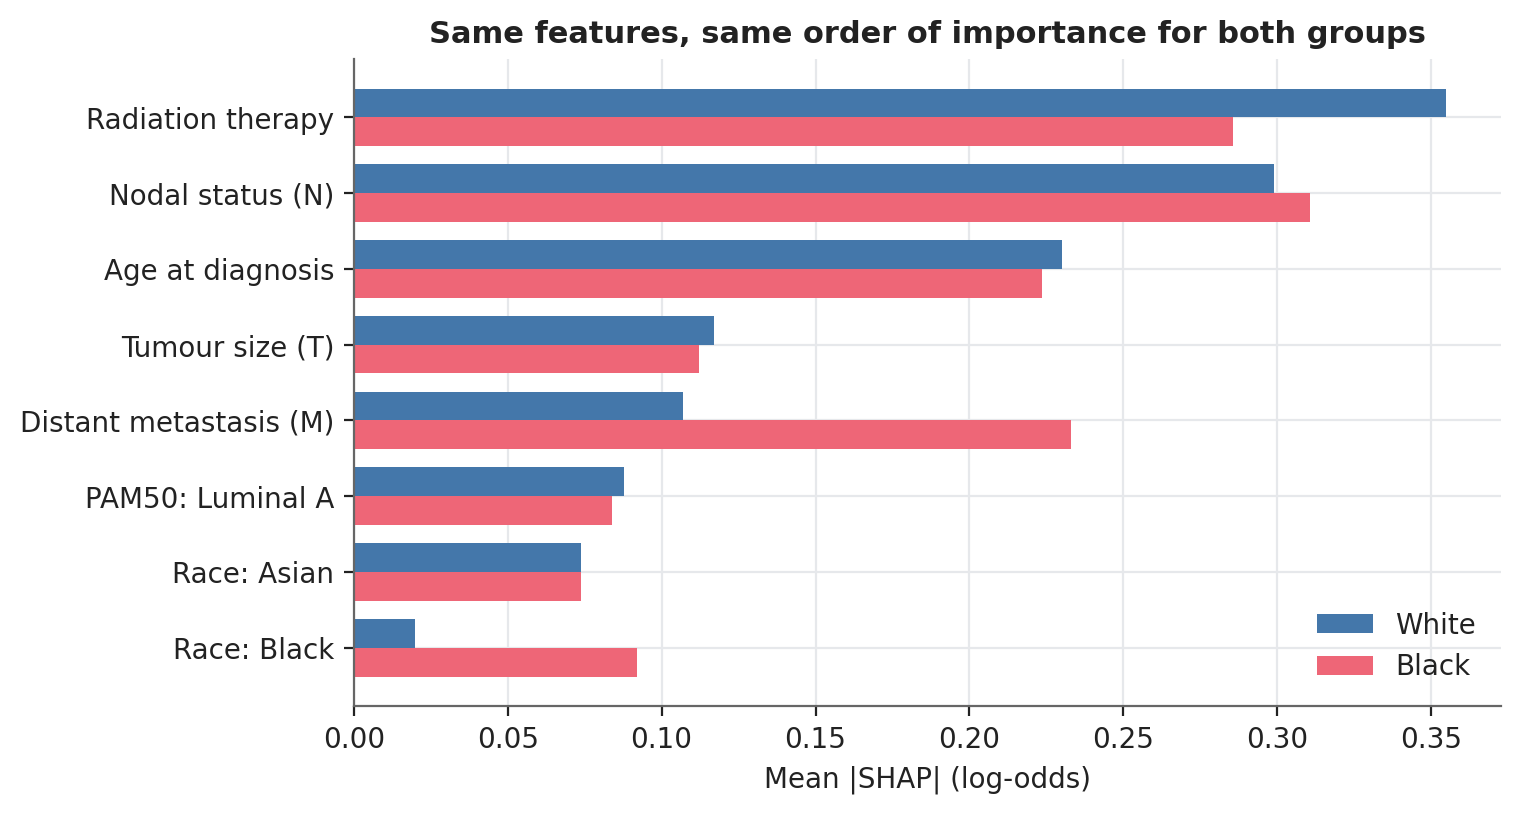

,mean_shap_White,mean_shap_Black,contribution_to_gap,label
race_black,-0.014,0.079,0.092,Race: Black
m_stage,-0.058,-0.147,-0.089,Distant metastasis (M)
sub_luma,-0.017,0.017,0.034,PAM50: Luminal A
radiation,-0.135,-0.162,-0.028,Radiation therapy
age,-0.047,-0.059,-0.012,Age at diagnosis
t_stage,-0.025,-0.032,-0.007,Tumour size (T)
sub_basal,-0.000,-0.003,-0.003,PAM50: Basal-like
sub_normal,-0.002,0.001,0.003,PAM50: Normal-like
sub_her2,-0.002,-0.000,0.002,PAM50: HER2-enriched
n_stage,-0.068,-0.066,0.002,Nodal status (N)


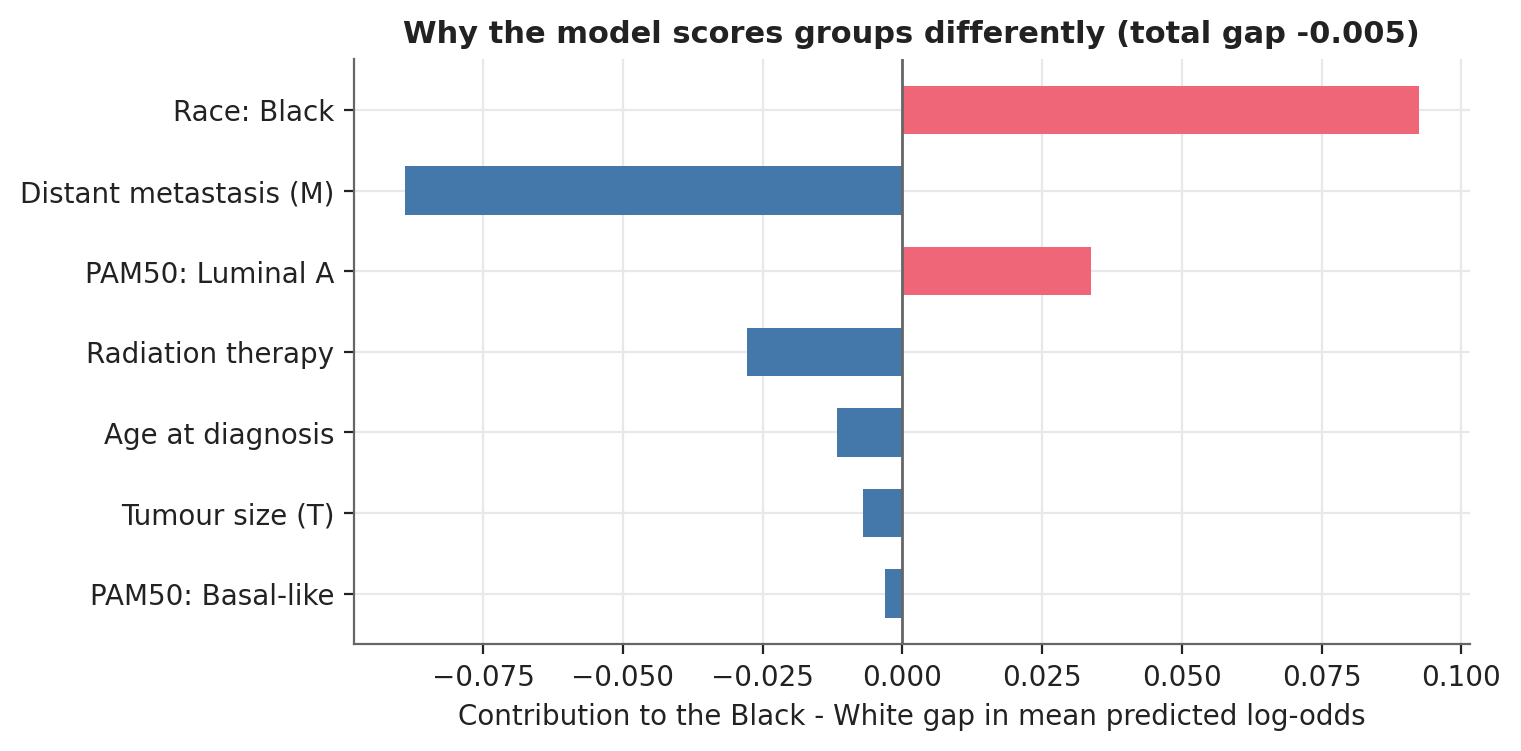

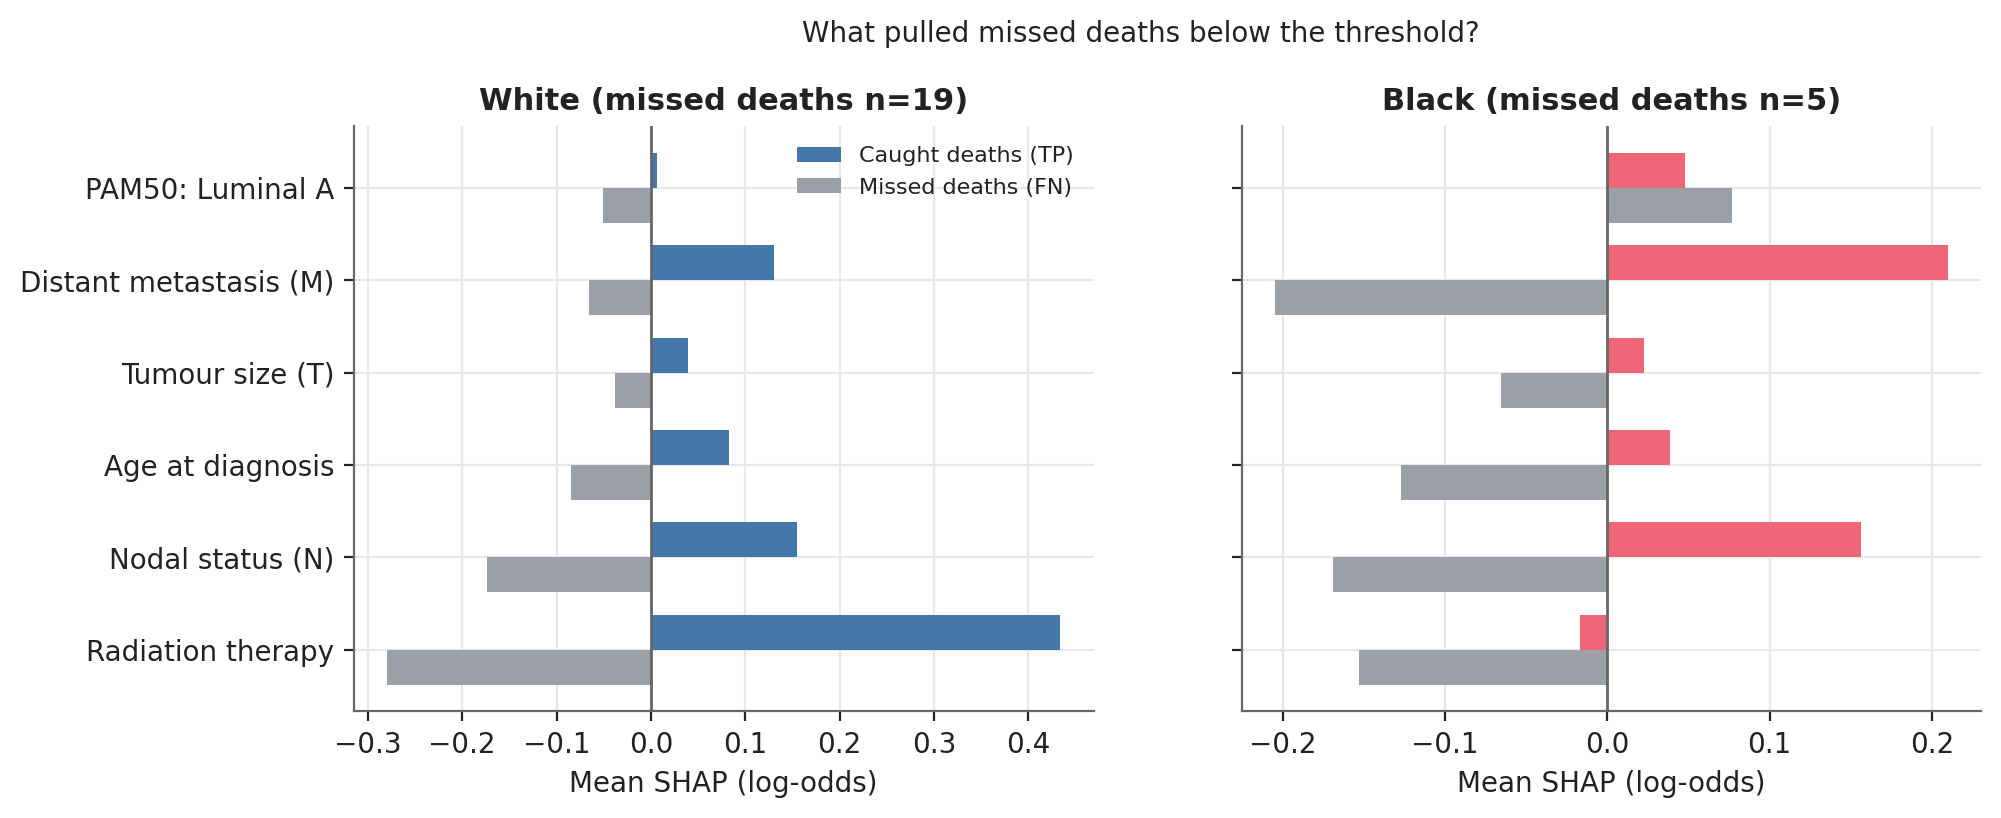

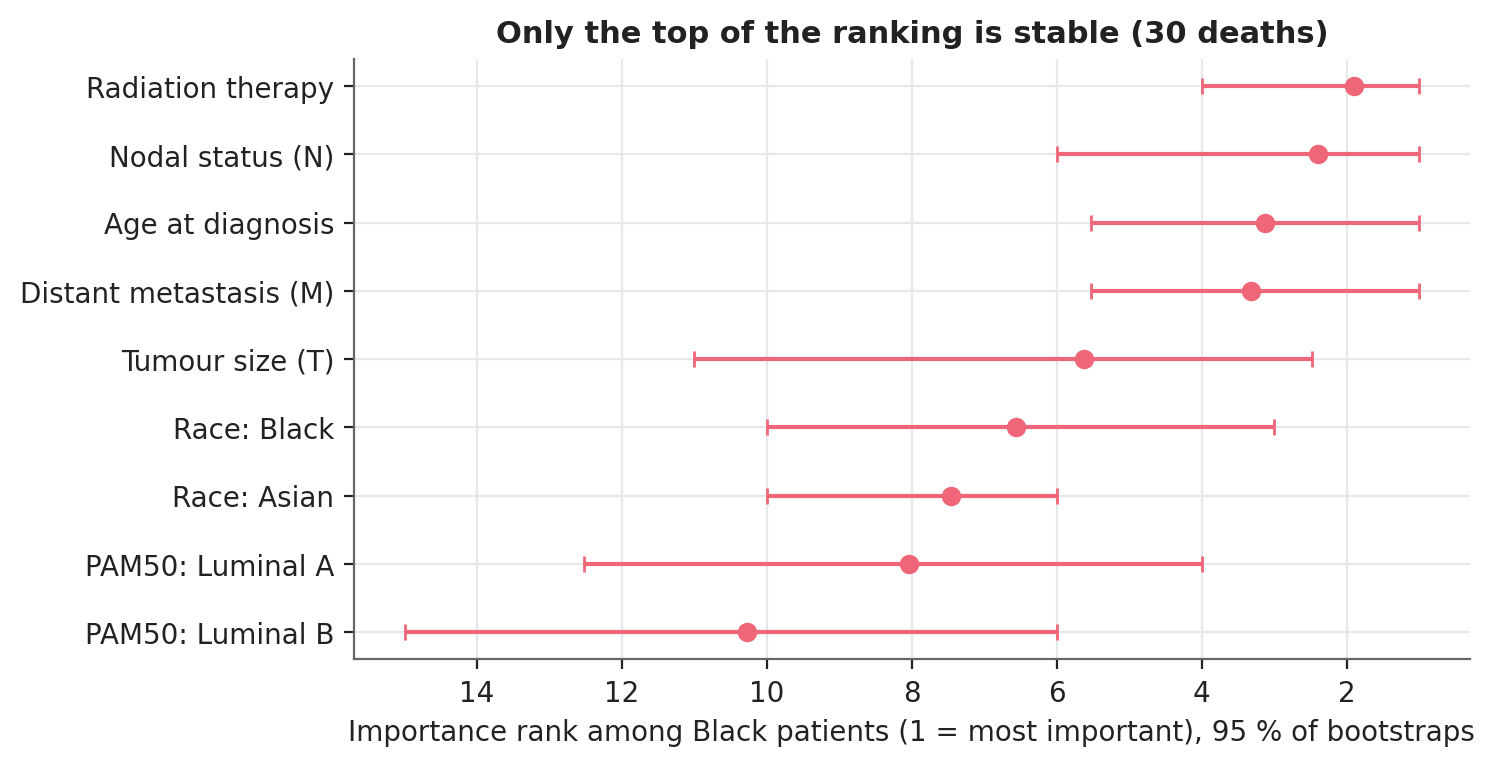

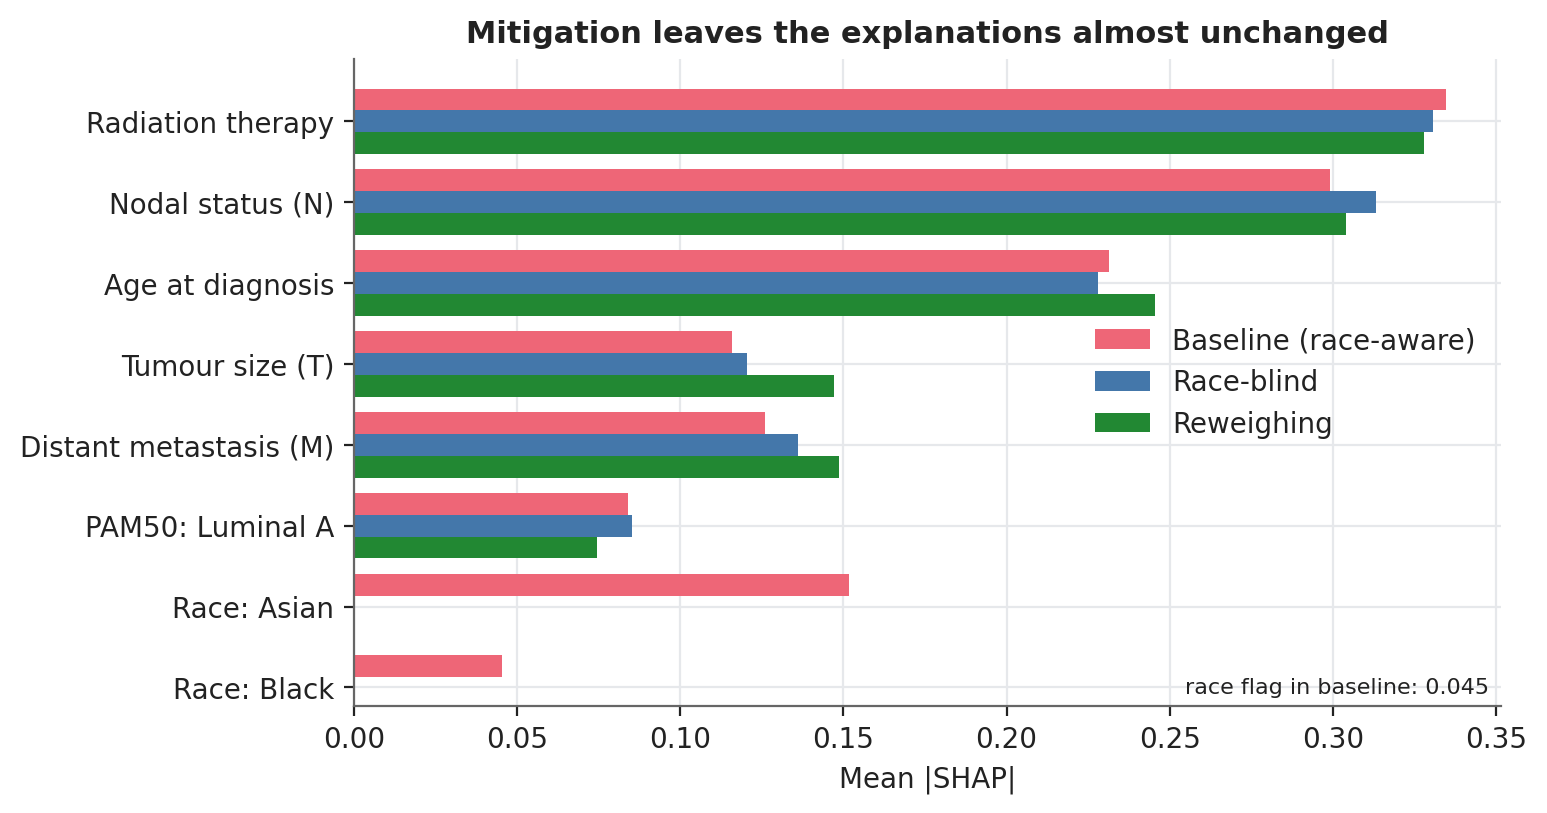

{'main_vs_blind': {'rank_corr': 0.9472527472527472, 'per_patient_rank_corr': 0.840603635995341}, 'main_vs_reweigh': {'rank_corr': 0.9824175824175824, 'per_patient_rank_corr': 0.9393123006026233}}


In [18]:
display(s.imp_group.round(3)); plots.fig_importance_group(s, s.fig); show("13_importance_by_race.png", 650)
display(s.gap_decomp.round(3)); plots.fig_gap_decomp(s, s.fig); show("16_risk_gap_decomposition.png", 650)
plots.fig_profile(s, s.fig); show("17_missed_deaths_profile.png", 950)
plots.fig_stability(s, s.fig); show("18_shap_stability_black.png", 650)
plots.fig_mitigation_explanations(s, s.fig); show("19_explanations_under_mitigation.png", 650); print(s.agreement)

## 7. Robustness (proposal 3.2.11 and sensitivity analyses)

target                 0.70   0.75   0.80   0.85   0.90   0.95
metric  strategy                                              
fpr_gap aware         0.063  0.051  0.035  0.023 -0.010 -0.002
        blind        -0.067 -0.052 -0.063 -0.075 -0.078 -0.073
        gthr          0.055  0.029  0.023 -0.053 -0.095 -0.129
        reweigh      -0.054 -0.062 -0.103 -0.105 -0.107 -0.103
        reweigh_gthr  0.059  0.043  0.042 -0.044 -0.095 -0.111
tpr_gap aware         0.056  0.071  0.100  0.092  0.048  0.012
        blind        -0.083 -0.036 -0.011  0.022  0.044  0.015
        gthr          0.012  0.009  0.057  0.047  0.010  0.012
        reweigh      -0.131 -0.100 -0.042  0.003  0.035  0.006
        reweigh_gthr -0.028 -0.021  0.070  0.042  0.044 -0.005

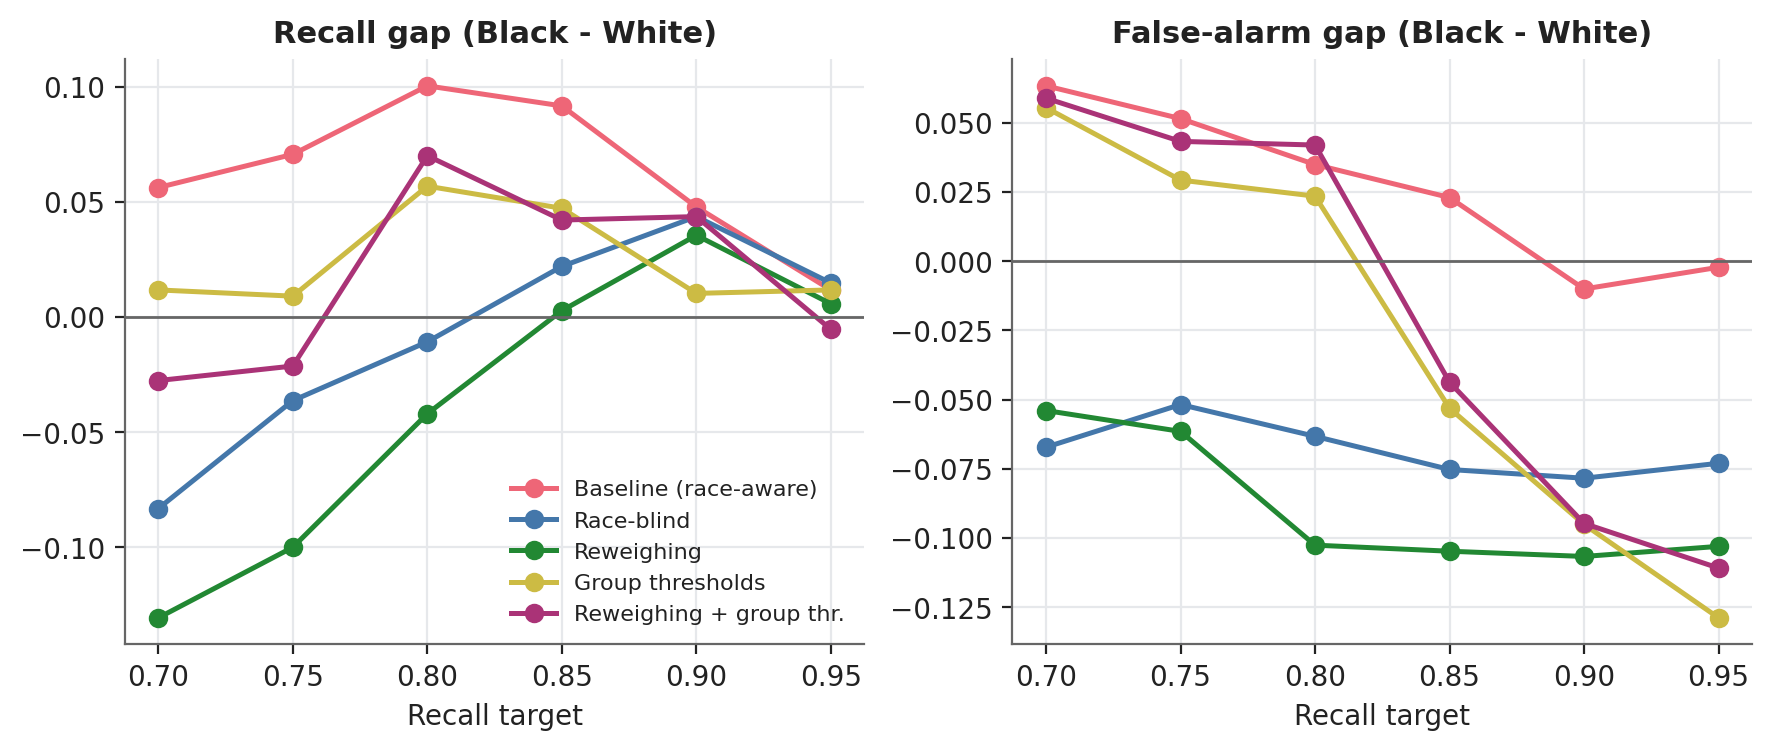

In [19]:
display(s.sweep_table[s.sweep_table.metric.isin(["tpr_gap", "fpr_gap"])].pivot_table(index=["metric", "strategy"], columns="target", values="estimate").round(3))
plots.fig_sweep(s, s.fig); show("08_recall_target_sweep.png", 950)

,strategy,metric,estimate,lo,hi,analysis
9,aware,tpr_gap,0.072,-0.046,0.172,"settled outcome (died or >= 24 mo follow-up), n=580"
10,aware,fpr_gap,0.046,-0.060,0.155,"settled outcome (died or >= 24 mo follow-up), n=580"
22,blind,tpr_gap,-0.077,-0.231,0.053,"settled outcome (died or >= 24 mo follow-up), n=580"
23,blind,fpr_gap,-0.047,-0.148,0.051,"settled outcome (died or >= 24 mo follow-up), n=580"
35,reweigh,tpr_gap,-0.109,-0.270,0.035,"settled outcome (died or >= 24 mo follow-up), n=580"
36,reweigh,fpr_gap,-0.074,-0.169,0.019,"settled outcome (died or >= 24 mo follow-up), n=580"
74,aware,tpr_gap,0.072,-0.033,0.160,"settled outcome (died or >= 36 mo follow-up), n=464"
75,aware,fpr_gap,0.078,-0.049,0.216,"settled outcome (died or >= 36 mo follow-up), n=464"
87,blind,tpr_gap,-0.077,-0.224,0.070,"settled outcome (died or >= 36 mo follow-up), n=464"
88,blind,fpr_gap,-0.024,-0.149,0.113,"settled outcome (died or >= 36 mo follow-up), n=464"


,strategy,group,n,deaths,recall,fpr,flag_rate
0,aware,EUR ancestry,807,116,0.783,0.524,0.562
1,aware,AFR / AFR-admixed ancestry,125,24,0.867,0.610,0.659
2,blind,EUR ancestry,807,116,0.807,0.561,0.596
3,blind,AFR / AFR-admixed ancestry,125,24,0.683,0.515,0.547
4,reweigh,EUR ancestry,807,116,0.809,0.574,0.608
5,reweigh,AFR / AFR-admixed ancestry,125,24,0.667,0.505,0.536
6,gthr,EUR ancestry,807,116,0.802,0.562,0.597
7,gthr,AFR / AFR-admixed ancestry,125,24,0.750,0.552,0.590
8,reweigh_gthr,EUR ancestry,807,116,0.802,0.557,0.592
9,reweigh_gthr,AFR / AFR-admixed ancestry,125,24,0.767,0.566,0.605


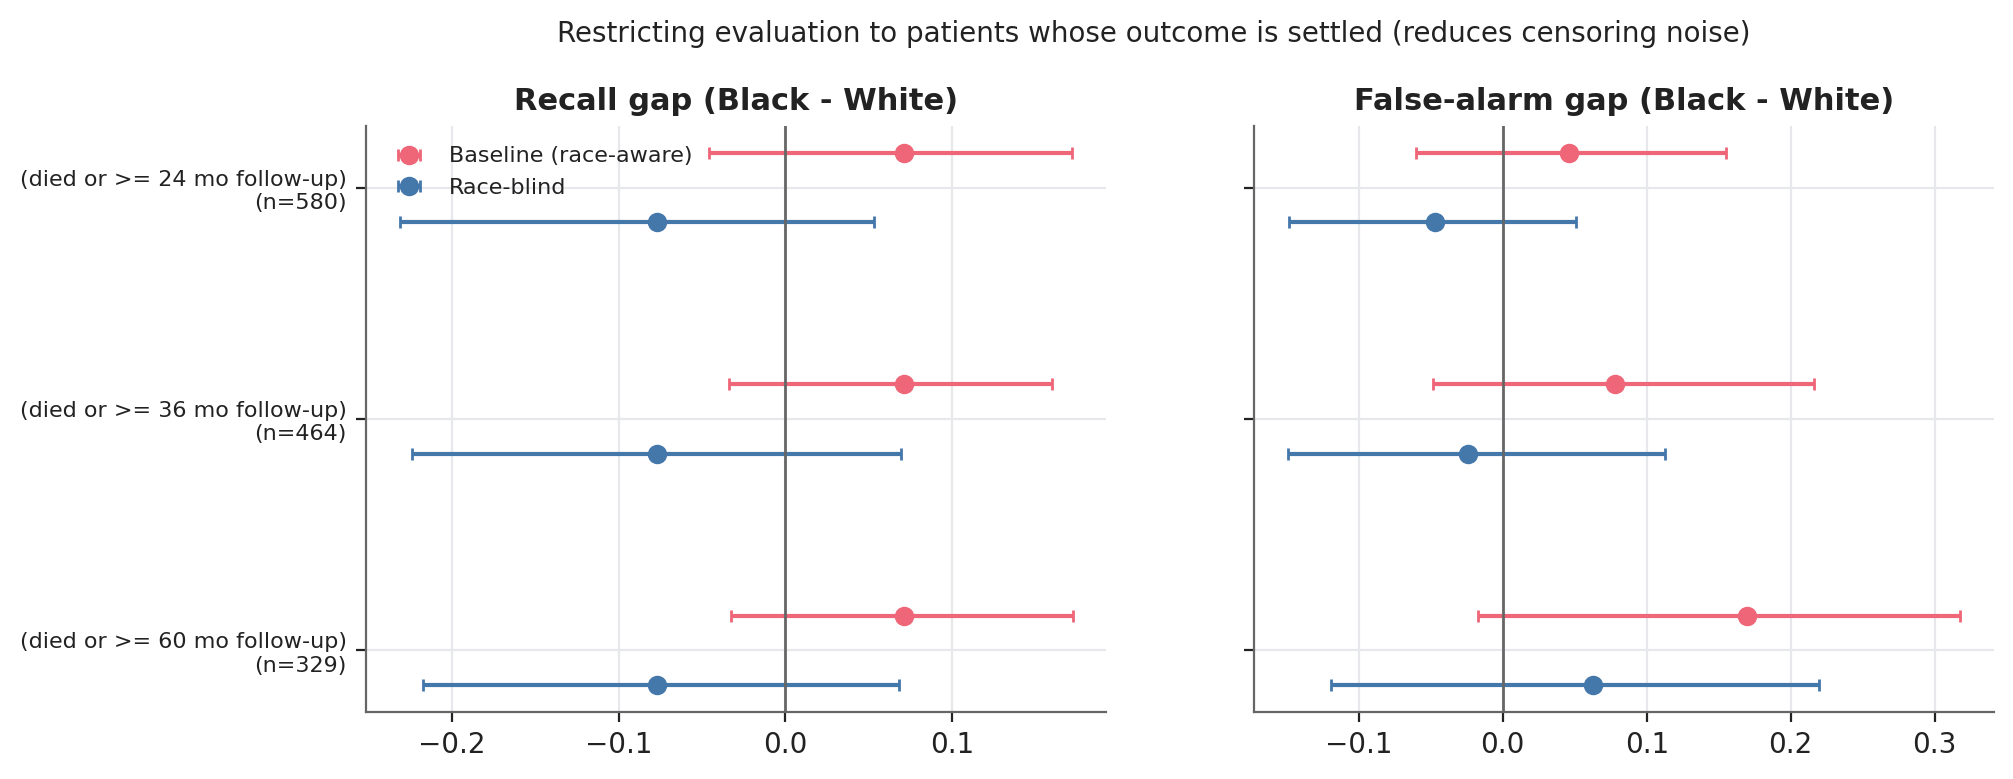

**Survival check (beyond the proposal's scope).** Harrell C-index, 3x5-fold CV: binary XGBoost score 0.717; XGBoost Cox survival objective 0.742. The binary label gives away little ranking information at this sample size.

In [20]:
display(s.sensitivity_table[s.sensitivity_table.metric.isin(["tpr_gap", "fpr_gap"]) & s.sensitivity_table.strategy.isin(["aware", "blind", "reweigh"])].round(3))
display(s.ancestry_table.round(3)); plots.fig_sensitivity(s, s.fig); show("11_sensitivity_settled.png", 950)
sv = s.res["survival"]
say(f"**Survival check (beyond the proposal's scope).** Harrell C-index, 3x5-fold CV: binary XGBoost score {sv['c_index_binary']:.3f}; XGBoost Cox survival objective {sv['c_index_cox']:.3f}. "
    "The binary label gives away little ranking information at this sample size.")

## 8. Compare with the audit-hardened specification (read from the saved run; this notebook does not overwrite any artifact)

In [21]:
h = joblib.load(ART_ROOT / "hardened" / "_study.joblib")
rows = []
for name, st_ in [("As proposed (Table 3.2)", s), ("Audit-hardened", h)]:
    o = st_.res["cv_overall"]["aware"]; c = st_.res["cv"]["aware"]
    rows.append({"specification": name, "AUC-ROC": o["auc_roc"][0], "PR-AUC": o["pr_auc"][0], "recall": o["recall"][0], "precision": o["precision"][0],
                 "flagged": o["flag_rate"][0], "recall gap B-W": c["tpr_gap"], "false-alarm gap B-W": c["fpr_gap"], "top SHAP feature": st_.alignment.feature.iloc[0]})
display(pd.DataFrame(rows).round(3))

,specification,AUC-ROC,PR-AUC,recall,precision,flagged,recall gap B-W,false-alarm gap B-W,top SHAP feature
0,As proposed (Table 3.2),0.747,0.457,0.792,0.202,0.546,0.072,0.014,Radiation therapy
1,Audit-hardened,0.662,0.307,0.812,0.175,0.645,0.020,0.050,Age at diagnosis


In [22]:
say("### Findings (generated)\n"
    f"* As proposed: AUC {s.res['cv_overall']['aware']['auc_roc'][0]:.2f}, PR-AUC {s.res['cv_overall']['aware']['pr_auc'][0]:.2f} (no-skill {s.res['flow']['prevalence']:.2f}); audit-hardened: AUC {h.res['cv_overall']['aware']['auc_roc'][0]:.2f}.\n"
    f"* Top SHAP feature as proposed: **{s.alignment.feature.iloc[0]}**; hardened: **{h.alignment.feature.iloc[0]}**.\n"
    f"* Recall gap (as proposed) {s.res['cv']['aware']['tpr_gap']:+.3f}, CI {s.res['cv']['aware']['tpr_gap_ci'][0]:+.3f} to {s.res['cv']['aware']['tpr_gap_ci'][1]:+.3f}; false-alarm gap {s.res['cv']['aware']['fpr_gap']:+.3f}.")

### Findings (generated)
* As proposed: AUC 0.75, PR-AUC 0.46 (no-skill 0.14); audit-hardened: AUC 0.66.
* Top SHAP feature as proposed: **Radiation therapy**; hardened: **Age at diagnosis**.
* Recall gap (as proposed) +0.072, CI -0.042 to +0.170; false-alarm gap +0.014.